# Growth and Treatment Relationships
From the [WGCNA](https://github.com/jgmcdonough/CE24_RNA-seq/tree/main/analysis/diff_expression/phase2_v_phase2/new_refGenome/wgcna) analysis, there are some interesting patterns that emerge with gene modules that are significantly correlated with tissue/shell growth and treatments. Here, I want to understand the relationship between growth and treatments to help provide context to the WGCNA results.

## 0. load libraries

In [2]:
library(tidyverse)
library(cowplot) # add plots together
library(grid)
library(plotrix) # for std.error
library(RColorBrewer)

# for stat testing
library(lme4) # for linear mixed effects model
library(ggpubr)
library(car)
library(rstatix)

# Phase 2 oysters
The phase 2 oysters only have growth data for phase 2 and not phase 1. 

## 1. load CSVs
reading in the metadata generated from WGCNA - contains the treatment and growth data for the same oysters that were used in the WGCNA analysis

In [ ]:
data <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/wgcna/outputs/p2.wgcna_metadata.csv') %>%
distinct(Sample, .keep_all = TRUE)

dim(data)
head(data)

limit the growth analysis to only those that I sequenced

#### set levels

In [ ]:
# DO
data$Phase1_DO <- factor(data$Phase1_DO, 
                                        levels = c("normoxic", "hypoxic"))
data$Phase2_DO <- factor(data$Phase2_DO, 
                                        levels = c("normoxic", "hypoxic"))

# temp
data$Phase1_temp <- factor(data$Phase1_temp, 
                                        levels = c("ambient", "warm"))
data$Phase2_temp <- factor(data$Phase2_temp, 
                                        levels = c("ambient", "warm"))

# treatment interaction
data$Phase1_treatment <- factor(data$Phase1_treatment,
                                levels = c('control', 'warm', 'hypoxic', 'both'))
data$Phase2_treatment <- factor(data$Phase2_treatment,
                                levels = c('control', 'warm', 'hypoxic', 'both'))

## 2. plot

### violin plots

In [6]:
p2.data <- data %>%
select(-X, -Module, -Eigengene) %>%
pivot_longer(
    cols = c(Actual_shell_growth_mg, Actual_tissue_growth_mg, Ratio_tissue_shell_mg),
    names_to = 'Growth_metric',
    values_to = 'Growth_mg'
    )

head(p2.data)

Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,combo_trtmt,Growth_metric,Growth_mg
<chr>,<fct>,<fct>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<chr>,<chr>,<dbl>
B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,Actual_shell_growth_mg,210.2755200
B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,Actual_tissue_growth_mg,120.7244800
B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,Ratio_tissue_shell_mg,0.5741252
B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,Actual_shell_growth_mg,315.8883000
B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,Actual_tissue_growth_mg,85.6117000
B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,Ratio_tissue_shell_mg,0.2710189


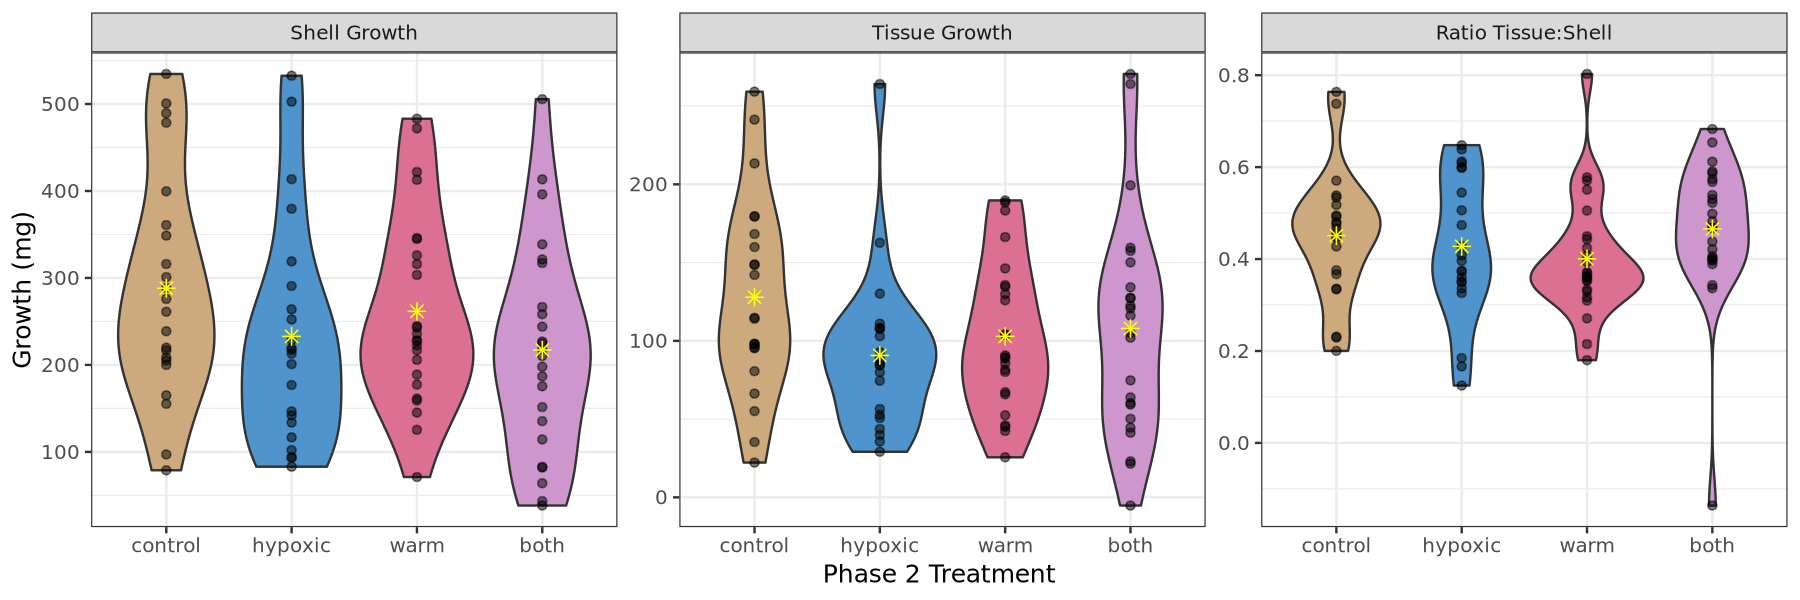

In [7]:
options(repr.plot.height = 5, repr.plot.width = 15)

p2.data$Phase2_treatment <- factor(p2.data$Phase2_treatment, levels = c('control', 'hypoxic', 'warm', 'both'))

# change facet wrap labels
custom_labels <- as_labeller(c(
  "Actual_shell_growth_mg" = "Shell Growth",
  "Actual_tissue_growth_mg" = "Tissue Growth",
  "Ratio_tissue_shell_mg" = "Ratio Tissue:Shell"
))

ggplot(p2.data, aes(x = Phase2_treatment, y = Growth_mg, fill = Phase2_treatment)) +
geom_violin() +
geom_point(alpha=0.5) +
stat_summary(
    fun = "mean", 
    geom = "point", 
    shape = 8,      # asterick shape
    size = 3,        # Size of the point
    color = "yellow"  # Outline color
  ) +
scale_fill_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
guides(fill = 'none') +
facet_wrap(~Growth_metric, 
           scales = 'free',
          labeller = custom_labels) +
theme_bw(base_size = 15) +
labs(x = 'Phase 2 Treatment',
    y = 'Growth (mg)')

for **phase 2 oysters**, when we ignore phase 1 and only look at the growth of phase 2, similar trends appear for tissue and shell growth (control oysters have higher growth than all stressed oysters; growth in warm oysters is a *little* higher than hypoxic oysters)

I think this is probably why when we look at the module-trait relationship matrix from [wgcna](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/phase2_v_phase2/wgcna/prefilter_newRef_wgcna_p2.ipynb), the shell and tissue growth are often correlated in the same direction in the same modules (black, blue, red, turquoise) - there are only 2 modules (lightcyan and midnightblue) that are only correlated with shell growth and not tissue growth

add phase 1 info:

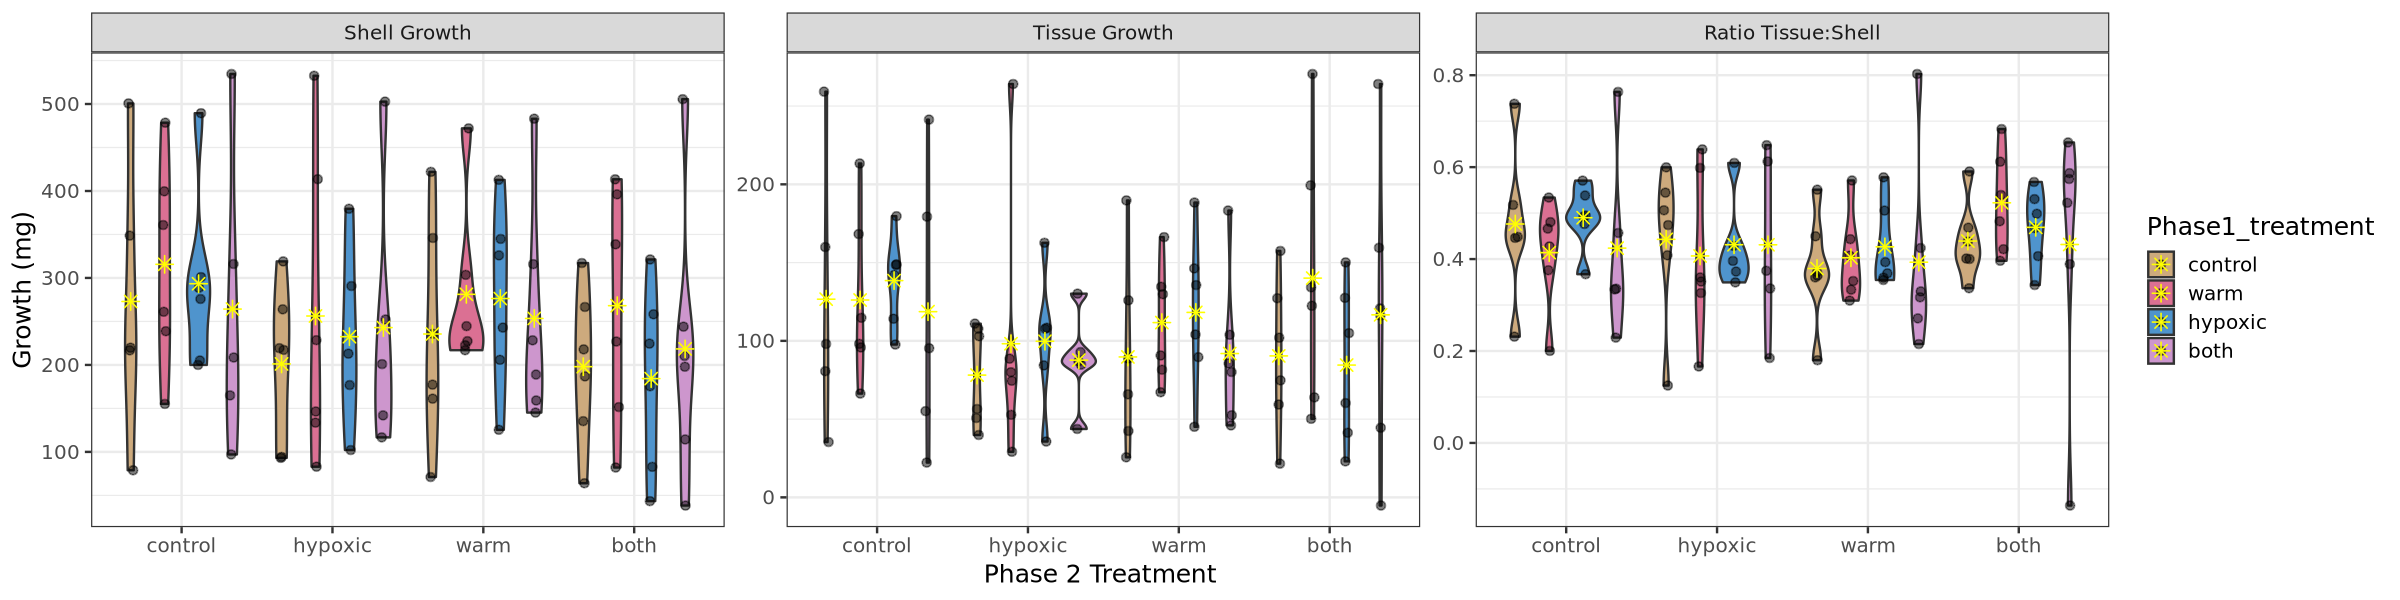

In [8]:
options(repr.plot.height = 5, repr.plot.width = 20)

p2.data$Phase2_treatment <- factor(p2.data$Phase2_treatment, levels = c('control', 'hypoxic', 'warm', 'both'))

# change facet wrap labels
custom_labels <- as_labeller(c(
  "Actual_shell_growth_mg" = "Shell Growth",
  "Actual_tissue_growth_mg" = "Tissue Growth",
  "Ratio_tissue_shell_mg" = "Ratio Tissue:Shell"
))

ggplot(p2.data, aes(x = Phase2_treatment, y = Growth_mg, fill = Phase1_treatment)) +
  geom_violin(position = position_dodge(width = 0.9)) +
  geom_point(
    alpha = 0.5,
    position = position_jitterdodge(
      jitter.width = 0.1,
      dodge.width = 0.9
    )
  ) +
  stat_summary(
    fun = "mean",
    geom = "point",
    shape = 8,
    size = 3,
    color = "yellow",
    position = position_dodge(width = 0.9)
  ) +
  scale_fill_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred",
                               "control" = "burlywood3", "both" = "plum3")) +
  #guides(fill = 'none') +
  facet_wrap(~Growth_metric, scales = 'free', labeller = custom_labels) +
  theme_bw(base_size = 15) +
  labs(x = 'Phase 2 Treatment', y = 'Growth (mg)')

### Shell Growth

#### A. only looking at Phase 2 treatment

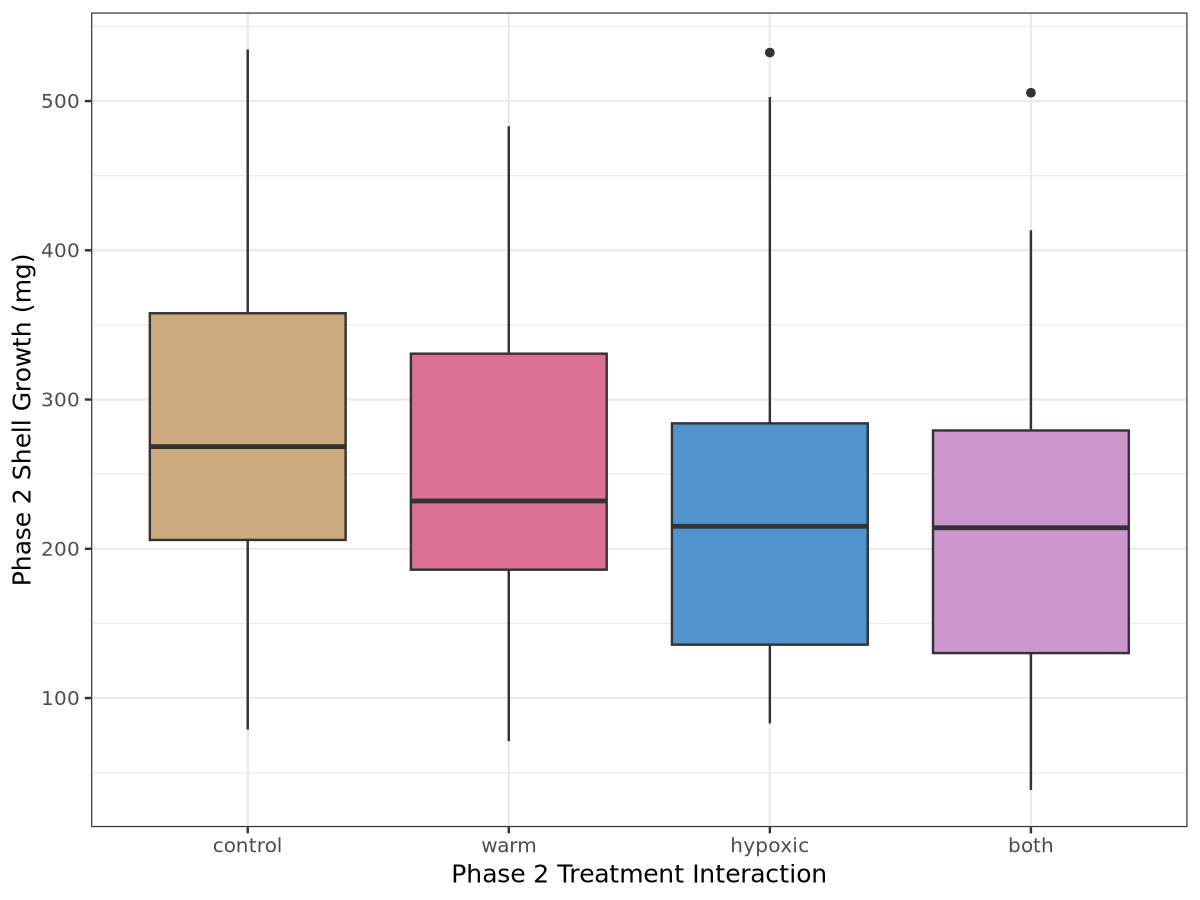

In [9]:
options(repr.plot.height = 7.5, repr.plot.width = 10)

s_phase2 <- ggplot(data, aes(x = Phase2_treatment, y = Actual_shell_growth_mg, fill = Phase2_treatment)) +
geom_boxplot() +
scale_fill_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
 guides(fill = "none") + # Remove legend for color
labs(y = 'Phase 2 Shell Growth (mg)',
     x = 'Phase 2 Treatment Interaction') +
theme_bw(base_size = 15)

s_phase2

In [10]:
summary(aov(Actual_shell_growth_mg ~ Phase2_treatment, data = data))

                 Df  Sum Sq Mean Sq F value Pr(>F)
Phase2_treatment  3   67626   22542   1.502   0.22
Residuals        88 1320862   15010               

average growth decreases with treatments but not significantly

#### B. Phase 1 and 2 treatment

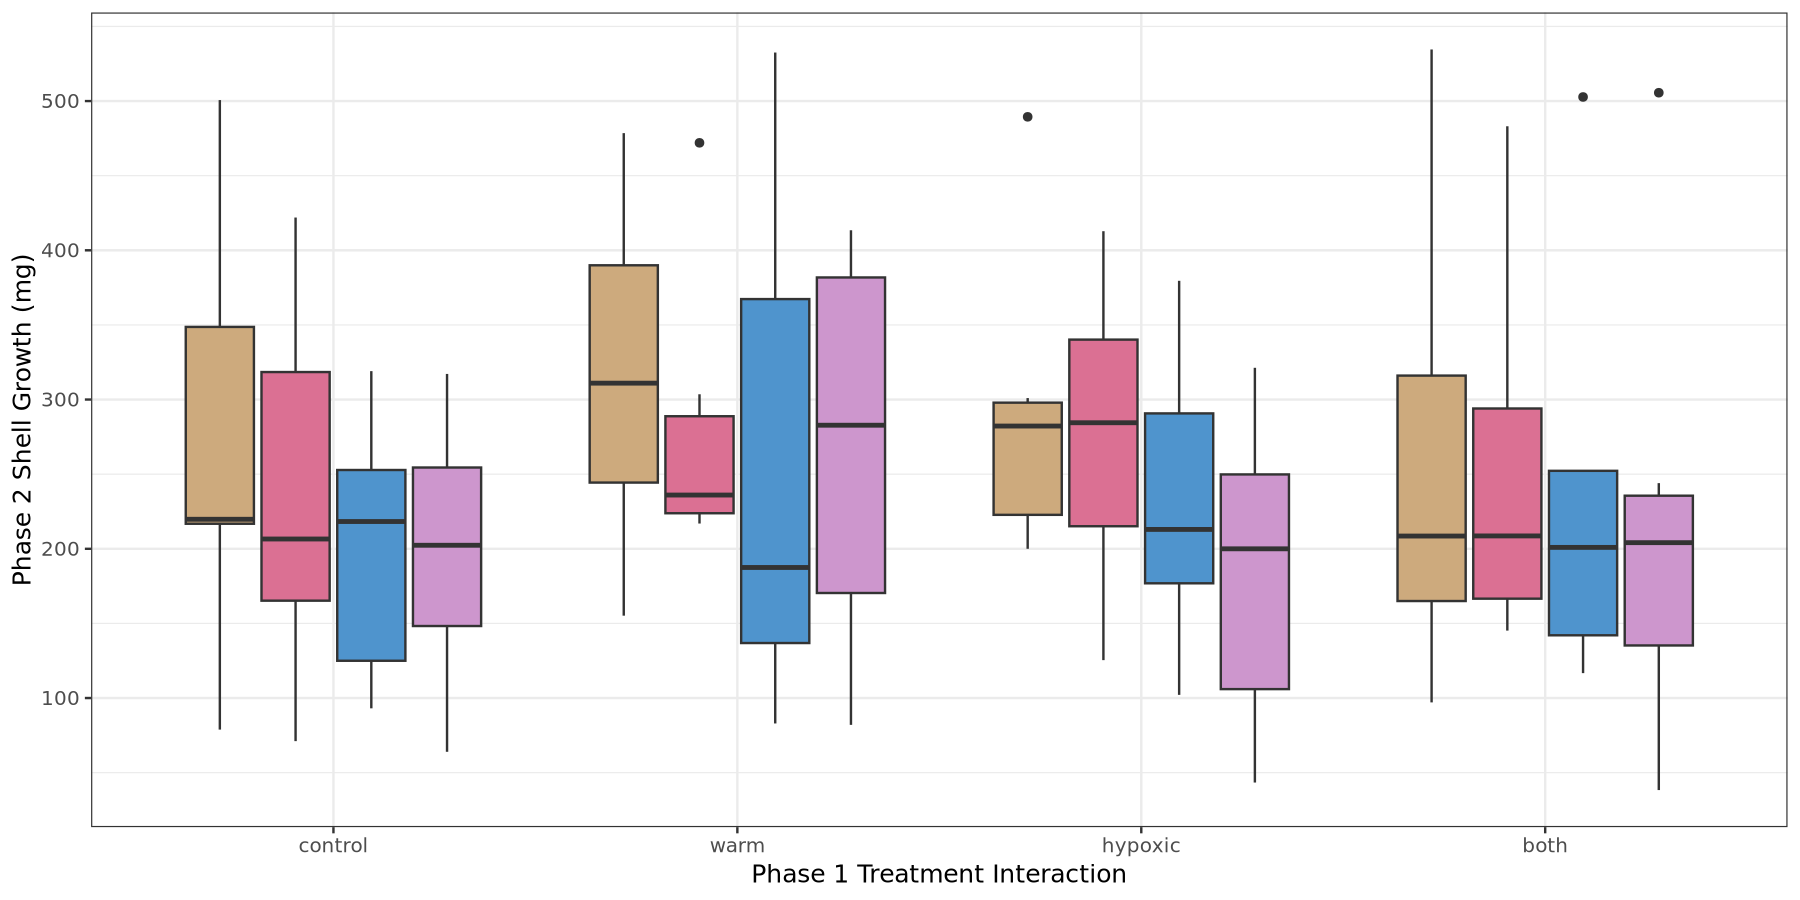

In [11]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

s_all <- ggplot(data, aes(x = Phase1_treatment, y = Actual_shell_growth_mg, fill = Phase2_treatment)) +
geom_boxplot() +
scale_fill_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
 guides(fill = "none") + # Remove legend for color
labs(y = 'Phase 2 Shell Growth (mg)',
     x = 'Phase 1 Treatment Interaction') +
theme_bw(base_size = 15)

s_all

In [12]:
summary(aov(Actual_shell_growth_mg ~ Phase1_treatment + Phase2_treatment + Phase1_treatment:Phase2_treatment, data = data))

                                  Df  Sum Sq Mean Sq F value Pr(>F)
Phase1_treatment                   3   37503   12501   0.748  0.527
Phase2_treatment                   3   65692   21897   1.310  0.277
Phase1_treatment:Phase2_treatment  9   15340    1704   0.102  1.000
Residuals                         76 1269954   16710               

no significant differences of shell growth between treatments

#### C. Phase 2 temp

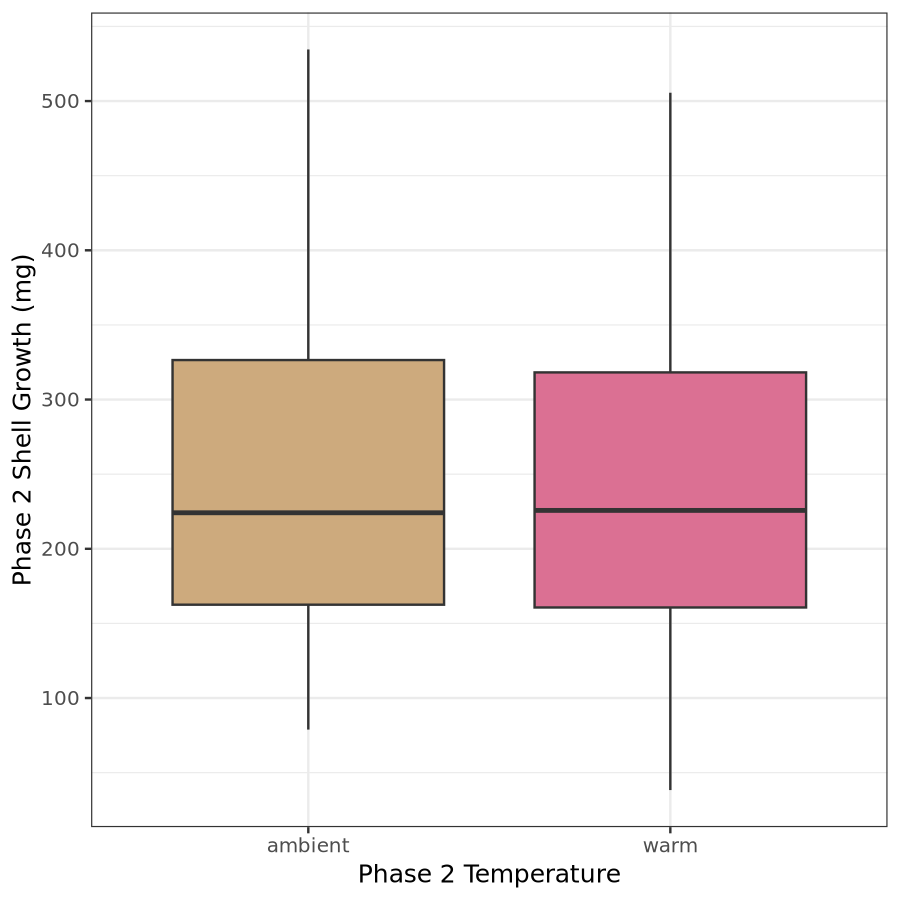

In [13]:
options(repr.plot.height = 7.5, repr.plot.width = 7.5)

s_p2temp <- ggplot(data, aes(x = Phase2_temp, y = Actual_shell_growth_mg, fill = Phase2_temp)) +
geom_boxplot() +
scale_fill_manual(values = c("warm" = "palevioletred", "ambient" = "burlywood3")) +
 guides(fill = "none") + # Remove legend for color
labs(y = 'Phase 2 Shell Growth (mg)',
     x = 'Phase 2 Temperature') +
theme_bw(base_size = 15)

s_p2temp

In [14]:
summary(aov(Actual_shell_growth_mg ~ Phase2_temp, data = data))

            Df  Sum Sq Mean Sq F value Pr(>F)
Phase2_temp  1   10198   10198   0.666  0.417
Residuals   90 1378290   15314               

no significant differences in shell growth between phase 2 temp treatments

#### D. Phase 2 DO

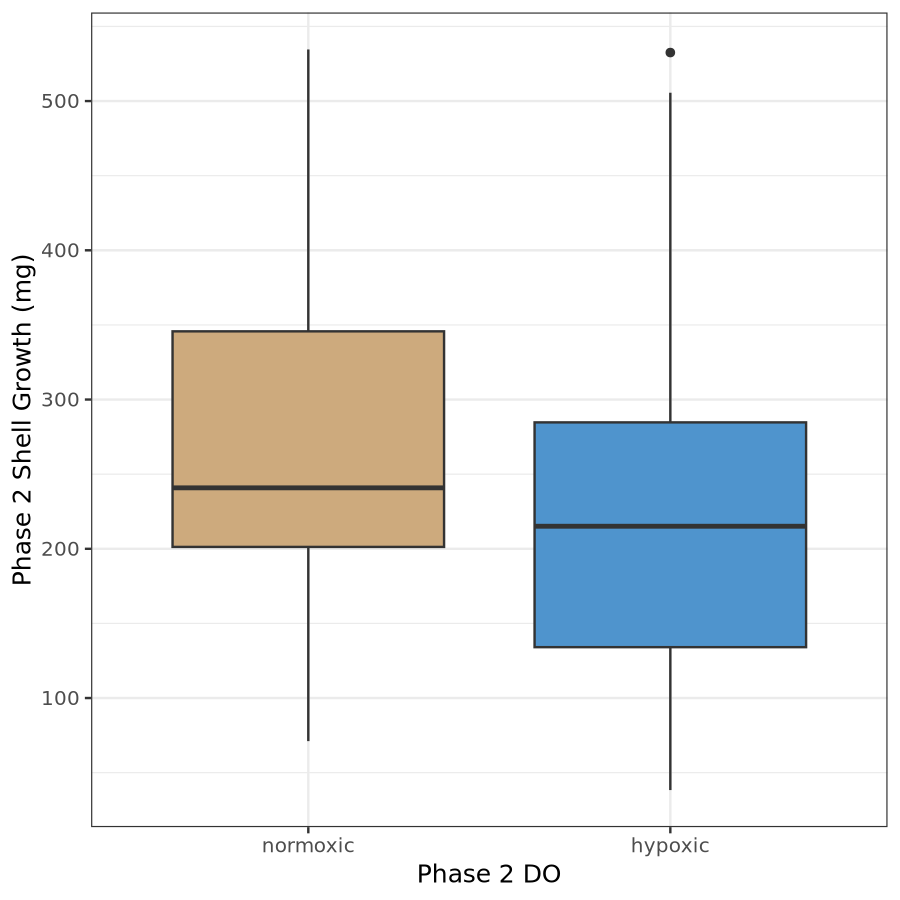

In [15]:
options(repr.plot.height = 7.5, repr.plot.width = 7.5)

s_p2do <- ggplot(data, aes(x = Phase2_DO, y = Actual_shell_growth_mg, fill = Phase2_DO)) +
geom_boxplot() +
scale_fill_manual(values = c("hypoxic" = "steelblue3", "normoxic" = "burlywood3")) +
 guides(fill = "none") + # Remove legend for color
labs(y = 'Phase 2 Shell Growth (mg)',
     x = 'Phase 2 DO') +
theme_bw(base_size = 15)

s_p2do

In [16]:
summary(aov(Actual_shell_growth_mg ~ Phase2_DO, data = data))

            Df  Sum Sq Mean Sq F value Pr(>F)  
Phase2_DO    1   56737   56737   3.834 0.0533 .
Residuals   90 1331751   14797                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

trending significant (?? lol) difference between shell growth between Phase 2 DO treatments

### Tissue Growth

#### A. only looking at Phase 2 treatment

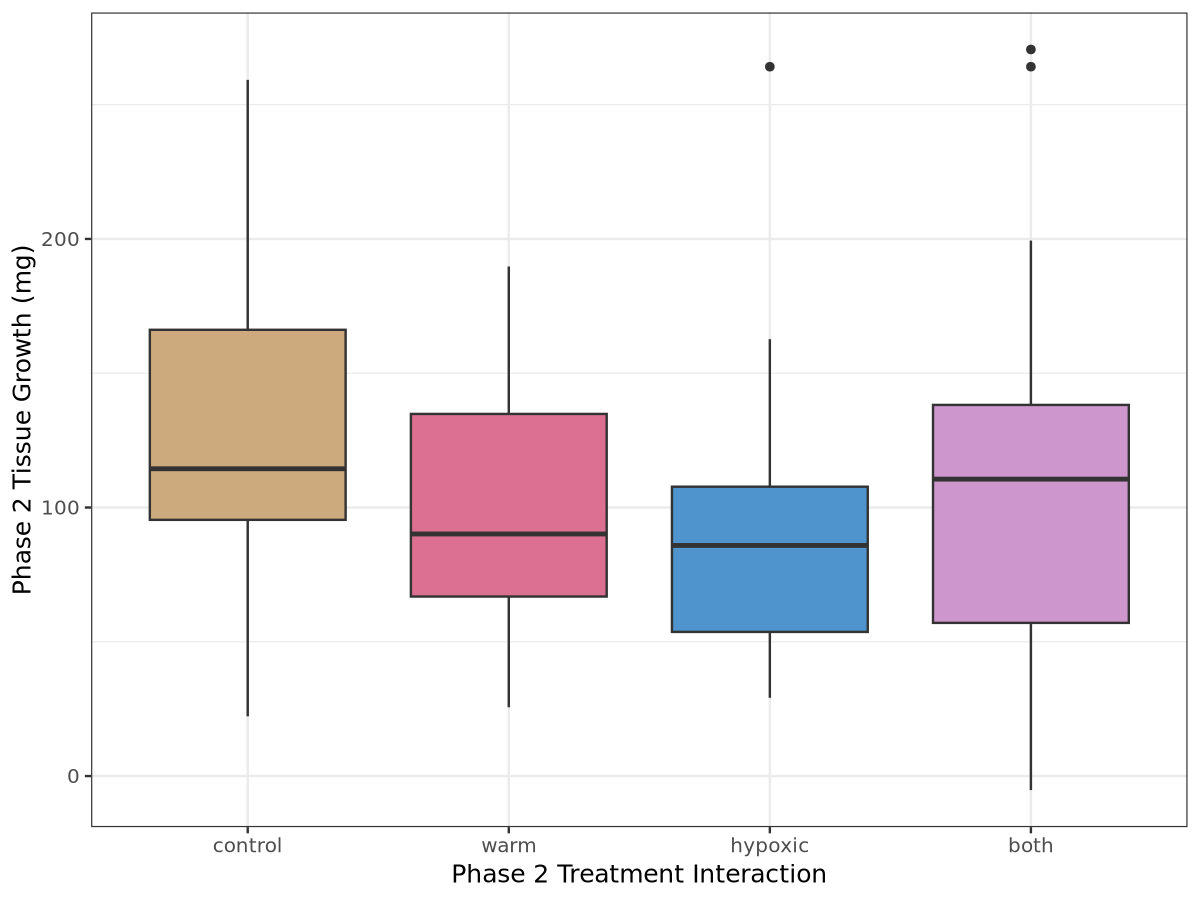

In [17]:
options(repr.plot.height = 7.5, repr.plot.width = 10)

t_phase2 <- ggplot(data, aes(x = Phase2_treatment, y = Actual_tissue_growth_mg, fill = Phase2_treatment)) +
#geom_point(alpha = 0.5) +
geom_boxplot() +
scale_fill_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
 guides(fill = "none") + # Remove legend for color
labs(y = 'Phase 2 Tissue Growth (mg)',
     x = 'Phase 2 Treatment Interaction') +
theme_bw(base_size = 15)

t_phase2

In [18]:
summary(aov(Actual_tissue_growth_mg ~ Phase2_treatment, data = data))

                 Df Sum Sq Mean Sq F value Pr(>F)
Phase2_treatment  3  15896    5299   1.524  0.214
Residuals        88 305961    3477               

average growth decreases with treatments but not significantly (and only for single stressors)

#### B. Phase 1 and 2 treatment

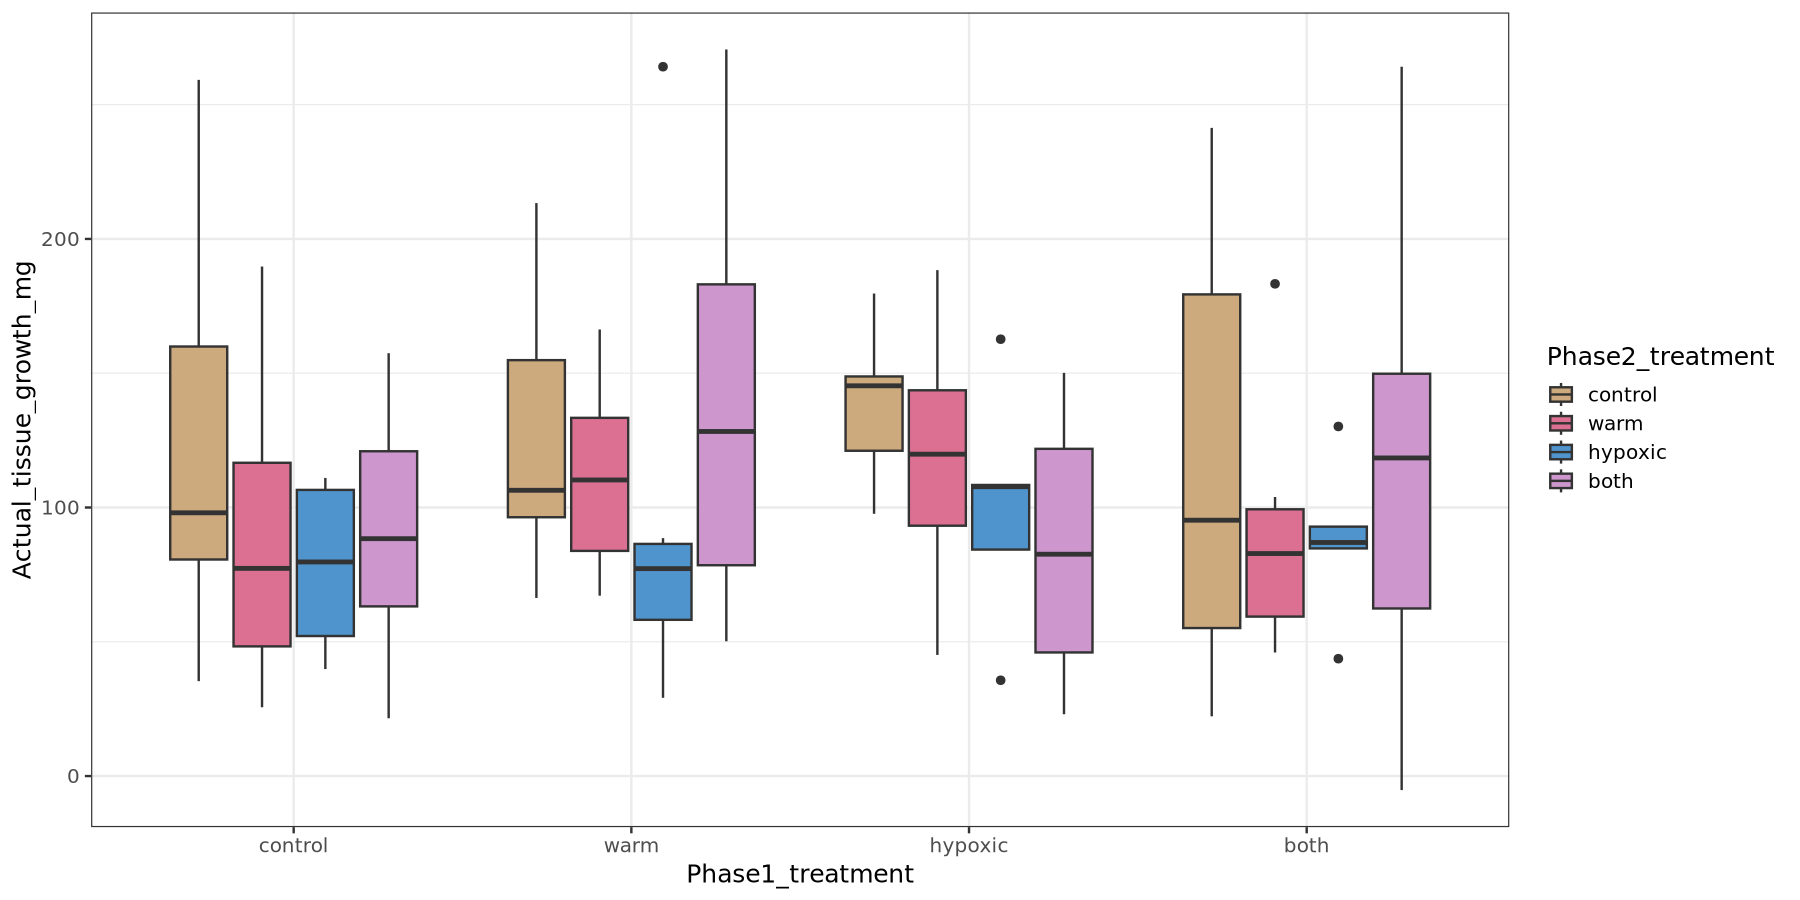

In [19]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

t_all <- ggplot(data, aes(x = Phase1_treatment, y = Actual_tissue_growth_mg, fill = Phase2_treatment)) +
geom_boxplot() +
scale_fill_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
theme_bw(base_size = 15)

t_all

In [20]:
summary(aov(Actual_tissue_growth_mg ~ Phase1_treatment + Phase2_treatment + Phase1_treatment:Phase2_treatment, data = data))

                                  Df Sum Sq Mean Sq F value Pr(>F)
Phase1_treatment                   3   7369    2456   0.649  0.586
Phase2_treatment                   3  15284    5095   1.346  0.266
Phase1_treatment:Phase2_treatment  9  11538    1282   0.339  0.959
Residuals                         76 287666    3785               

no significant differences of shell growth between treatments

#### C. Phase 2 temp

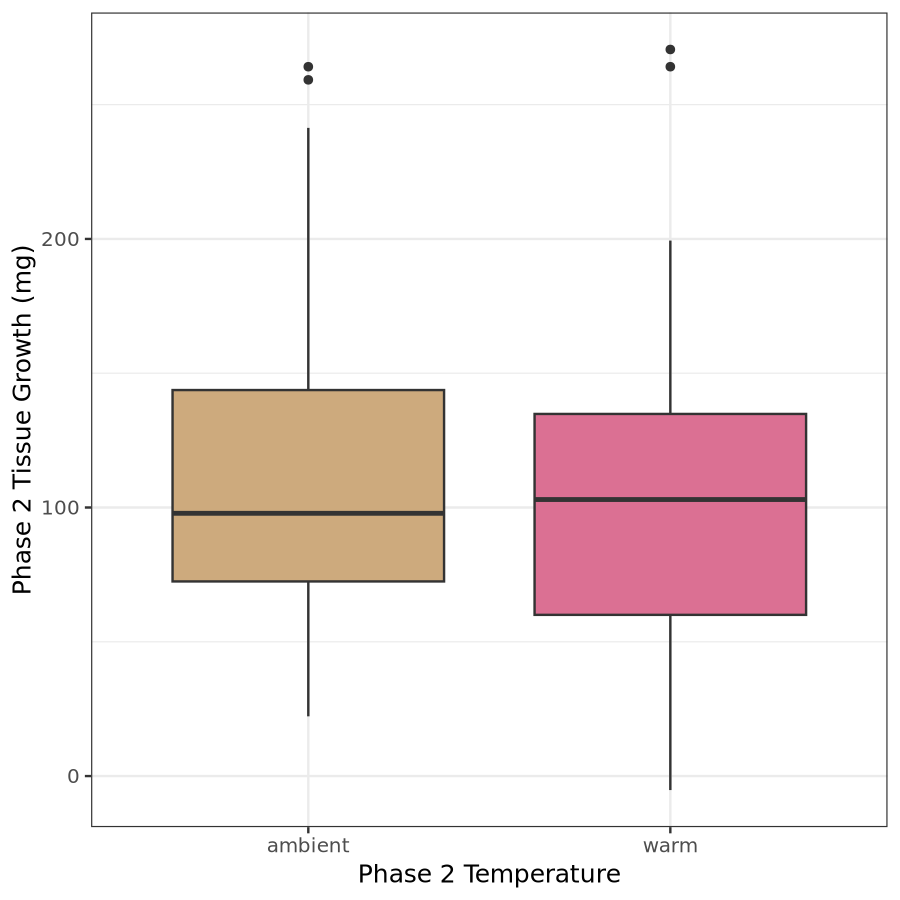

In [21]:
options(repr.plot.height = 7.5, repr.plot.width = 7.5)

t_p2temp <- ggplot(data, aes(x = Phase2_temp, y = Actual_tissue_growth_mg, fill = Phase2_temp)) +
geom_boxplot() +
scale_fill_manual(values = c("warm" = "palevioletred", "ambient" = "burlywood3")) +
 guides(fill = "none") + # Remove legend for color
labs(y = 'Phase 2 Tissue Growth (mg)',
     x = 'Phase 2 Temperature') +
theme_bw(base_size = 15)

t_p2temp

In [22]:
summary(aov(Actual_tissue_growth_mg ~ Phase2_temp, data = data))

            Df Sum Sq Mean Sq F value Pr(>F)
Phase2_temp  1    350     350   0.098  0.755
Residuals   90 321507    3572               

no significant differences in tissue growth between phase 2 temp treatments

#### D. Phase 2 DO

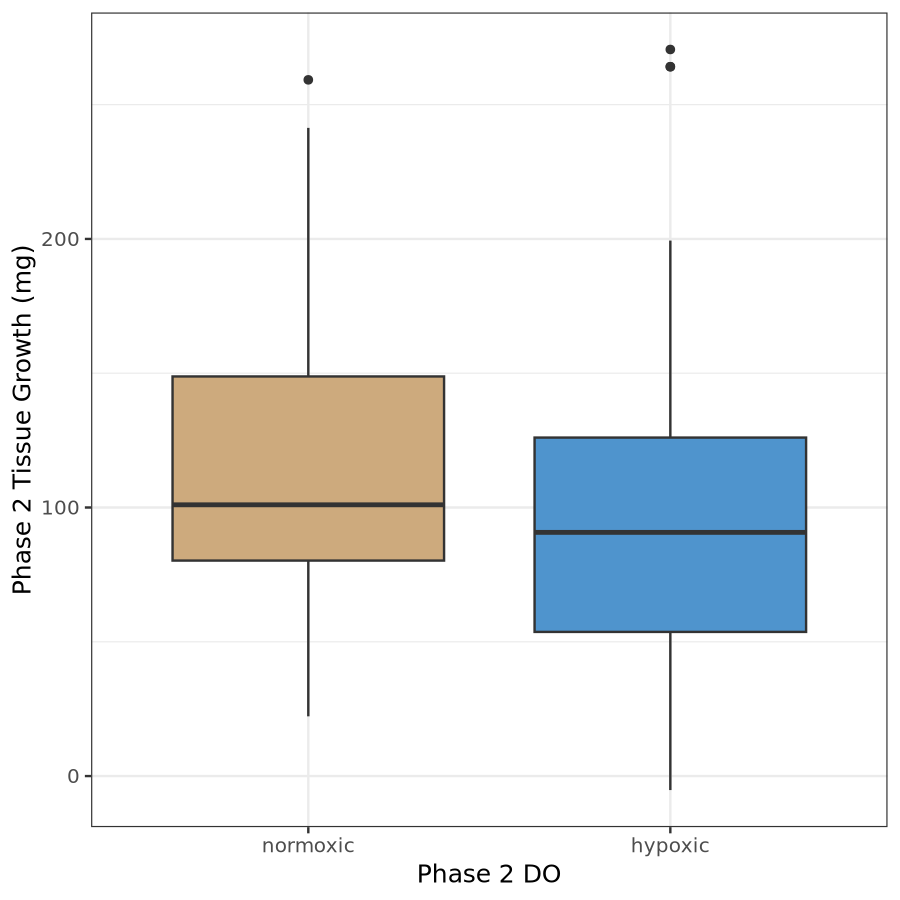

In [23]:
options(repr.plot.height = 7.5, repr.plot.width = 7.5)

t_p2do <- ggplot(data, aes(x = Phase2_DO, y = Actual_tissue_growth_mg, fill = Phase2_DO)) +
geom_boxplot() +
scale_fill_manual(values = c("hypoxic" = "steelblue3", "normoxic" = "burlywood3")) +
  guides(fill = "none") + # Remove legend for color
labs(y = 'Phase 2 Tissue Growth (mg)',
     x = 'Phase 2 DO') +
theme_bw(base_size = 15)

t_p2do

In [24]:
summary(aov(Actual_tissue_growth_mg ~ Phase2_DO, data = data))

            Df Sum Sq Mean Sq F value Pr(>F)
Phase2_DO    1   5296    5296   1.506  0.223
Residuals   90 316561    3517               

no significant difference in tissue growth between phase 2 DO treatments

make into bar plots instead of boxplots where the bar is the mean

### Isolate phase 2 treatment plots

In [25]:
plot_dat <- data %>%
  pivot_longer(
    cols = c(Actual_shell_growth_mg, Actual_tissue_growth_mg, Ratio_tissue_shell_mg),
    names_to = "Response",
    values_to = "Growth"
  )

phase_dat <- plot_dat %>%
  mutate(Predictor = "Phase",
         x = Phase2_treatment)

temp_dat <- plot_dat %>%
  mutate(Predictor = "Temperature",
         x = Phase2_temp)

do_dat <- plot_dat %>%
  mutate(Predictor = "DO",
         x = Phase2_DO)

facet_dat <- bind_rows(phase_dat, temp_dat, do_dat)

# set factor
facet_dat$Predictor <- factor(facet_dat$Predictor, levels = c('Phase','Temperature','DO'))


head(facet_dat)

X,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,combo_trtmt,Module,Eigengene,Response,Growth,Predictor,x
<int>,<chr>,<fct>,<fct>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<fct>,<fct>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_shell_growth_mg,210.2755200,Phase,both
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_tissue_growth_mg,120.7244800,Phase,both
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Ratio_tissue_shell_mg,0.5741252,Phase,both
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_shell_growth_mg,315.8883000,Phase,warm
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_tissue_growth_mg,85.6117000,Phase,warm
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Ratio_tissue_shell_mg,0.2710189,Phase,warm


In [26]:
summary_stats <- facet_dat %>%
  group_by(Predictor, x, Response) %>%
  mutate(
    mean_growth = mean(Growth, na.rm = TRUE),
    se_growth = std.error(Growth, na.rm = TRUE)) %>%
distinct(Response, Predictor, x, .keep_all = TRUE)

head(summary_stats)
     

X,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,combo_trtmt,Module,Eigengene,Response,Growth,Predictor,x,mean_growth,se_growth
<int>,<chr>,<fct>,<fct>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<fct>,<fct>,<dbl>,<dbl>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_shell_growth_mg,210.2755200,Phase,both,217.1962975,24.85370539
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_tissue_growth_mg,120.7244800,Phase,both,107.9078692,14.43237840
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Ratio_tissue_shell_mg,0.5741252,Phase,both,0.4655402,0.03268678
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_shell_growth_mg,315.8883000,Phase,warm,261.6172650,22.37629164
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_tissue_growth_mg,85.6117000,Phase,warm,102.8702350,9.86674954
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Ratio_tissue_shell_mg,0.2710189,Phase,warm,0.4004970,0.02679368


In [27]:
sumStats.16 <- facet_dat %>%
  group_by(combo_trtmt, Response) %>%
  mutate(
    mean_growth = mean(Growth, na.rm = TRUE),
    se_growth = std.error(Growth, na.rm = TRUE)) %>%
distinct(Response, combo_trtmt, .keep_all = TRUE)

head(sumStats.16)

X,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,combo_trtmt,Module,Eigengene,Response,Growth,Predictor,x,mean_growth,se_growth
<int>,<chr>,<fct>,<fct>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<fct>,<fct>,<dbl>,<dbl>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_shell_growth_mg,210.2755200,Phase,both,218.4036400,35.26852043
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_tissue_growth_mg,120.7244800,Phase,both,116.6296933,20.68932043
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Ratio_tissue_shell_mg,0.5741252,Phase,both,0.4316765,0.06464093
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_shell_growth_mg,315.8883000,Phase,warm,253.4231700,28.36180062
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_tissue_growth_mg,85.6117000,Phase,warm,91.8934967,10.99621470
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Ratio_tissue_shell_mg,0.2710189,Phase,warm,0.3932268,0.04698201


In [28]:
phase2_inter <- summary_stats %>%
filter(Predictor == 'Phase')
phase2_inter

# separate into two groups
p2_shell <- phase2_inter %>% filter(Response == 'Actual_shell_growth_mg')
p2_tissue <- phase2_inter %>% filter(Response == 'Actual_tissue_growth_mg')
p2_ts <- phase2_inter %>% filter(Response == 'Ratio_tissue_shell_mg')

X,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,combo_trtmt,Module,Eigengene,Response,Growth,Predictor,x,mean_growth,se_growth
<int>,<chr>,<fct>,<fct>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<fct>,<fct>,<dbl>,<dbl>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_shell_growth_mg,210.2755200,Phase,both,217.1962975,24.85370539
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_tissue_growth_mg,120.7244800,Phase,both,107.9078692,14.43237840
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Ratio_tissue_shell_mg,0.5741252,Phase,both,0.4655402,0.03268678
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_shell_growth_mg,315.8883000,Phase,warm,261.6172650,22.37629164
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_tissue_growth_mg,85.6117000,Phase,warm,102.8702350,9.86674954
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Ratio_tissue_shell_mg,0.2710189,Phase,warm,0.4004970,0.02679368
4,B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control,MEgrey60,0.04819095,Actual_shell_growth_mg,164.9902800,Phase,control,288.1788000,27.61175412
4,B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control,MEgrey60,0.04819095,Actual_tissue_growth_mg,55.1097200,Phase,control,127.9075636,13.37741694
4,B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control,MEgrey60,0.04819095,Ratio_tissue_shell_mg,0.3340180,Phase,control,0.4510664,0.03012957


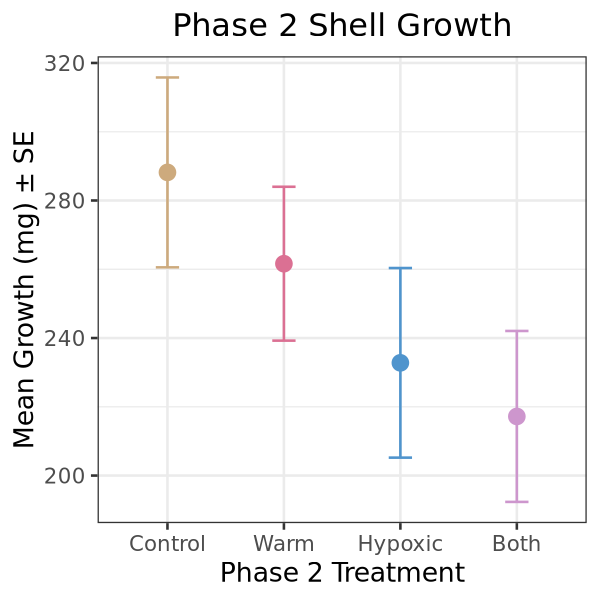

In [29]:
options(repr.plot.width = 5, repr.plot.height = 5)

shell <- ggplot(p2_shell, aes(x = x, y = mean_growth, color = x)) +
# Plot means as points
geom_point(size = 4, position = position_dodge(0.9)) + 
 # Error bars for SD
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
#scale_y_continuous(position = "right") +   # move y-axis to right 
scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
scale_x_discrete(labels = stringr::str_to_title) +
guides(fill = 'none') +
labs(x = 'Phase 2 Treatment',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 2 Shell Growth') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

shell

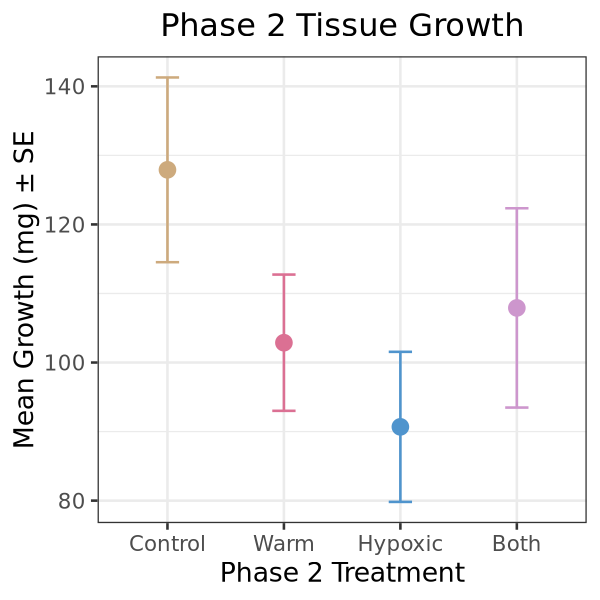

In [30]:
options(repr.plot.width = 5, repr.plot.height = 5)

tissue <- ggplot(p2_tissue, aes(x = x, y = mean_growth, color = x)) +
# Plot means as points
geom_point(size = 4, position = position_dodge(0.9)) + 
 # Error bars for SD
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
#scale_y_continuous(position = "right") +   # move y-axis to right 
scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
scale_x_discrete(labels = stringr::str_to_title) +
guides(fill = 'none') +
labs(x = 'Phase 2 Treatment',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 2 Tissue Growth') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

tissue

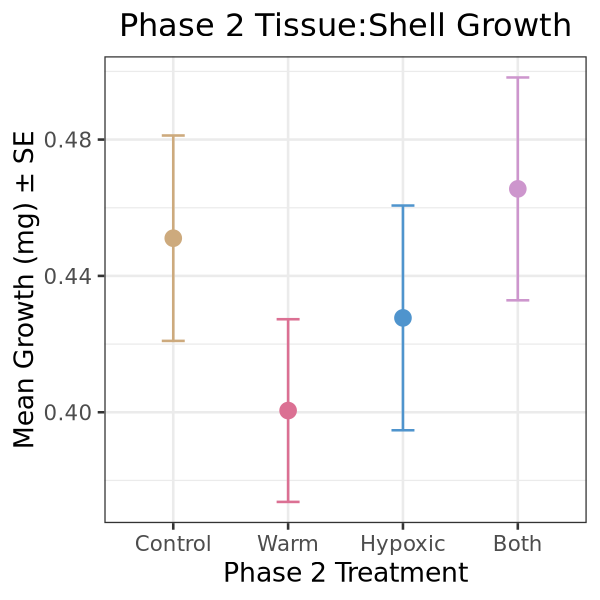

In [31]:
options(repr.plot.width = 5, repr.plot.height = 5)

t_s <- ggplot(p2_ts, aes(x = x, y = mean_growth, color = x)) +
# Plot means as points
geom_point(size = 4, position = position_dodge(0.9)) + 
 # Error bars for SD
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
#scale_y_continuous(position = "right") +   # move y-axis to right 
scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
scale_x_discrete(labels = stringr::str_to_title) +
guides(fill = 'none') +
labs(x = 'Phase 2 Treatment',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 2 Tissue:Shell Growth') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

t_s

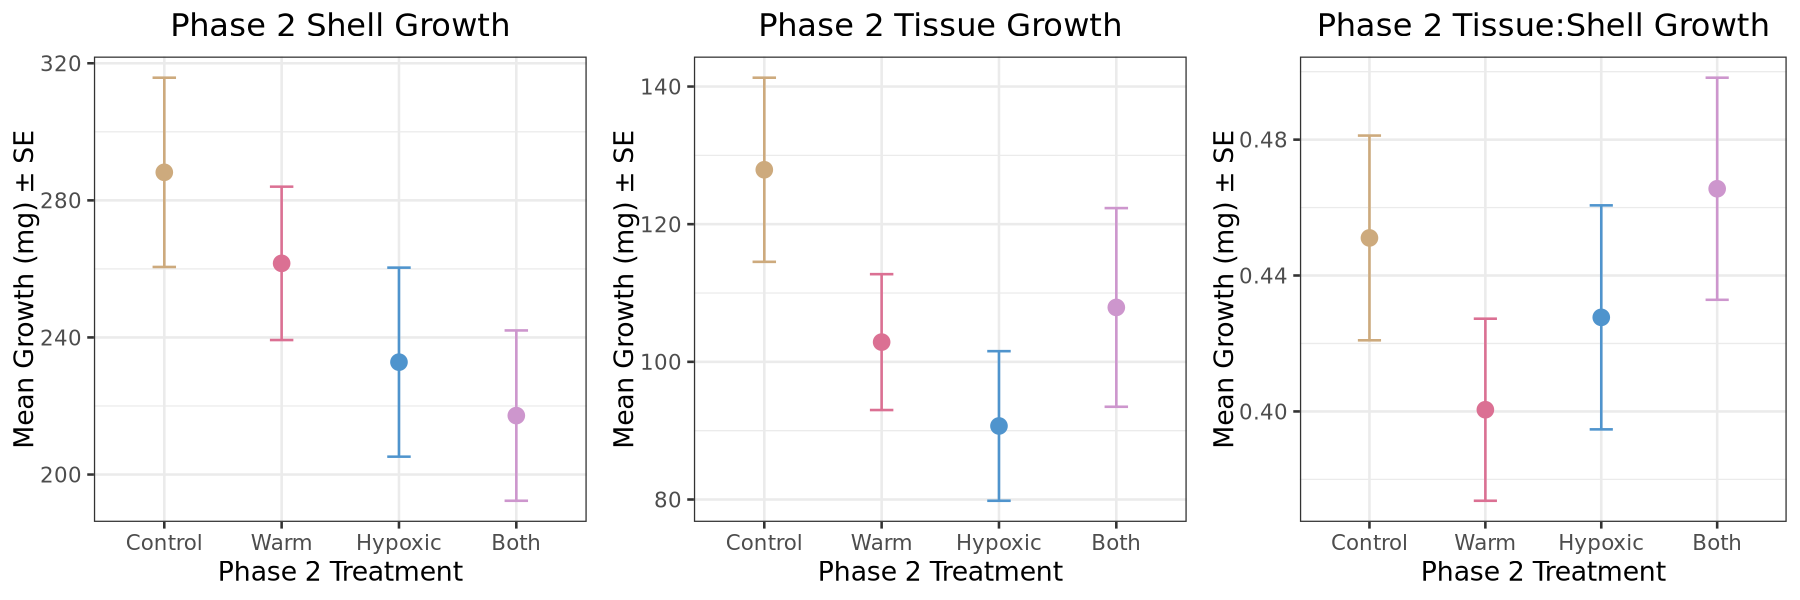

In [32]:
options(repr.plot.height = 5, repr.plot.width = 15)

plot1 <- plot_grid(shell, tissue, t_s, nrow = 1)
plot1

### Stat testing

In [34]:
m1 <- aov(Actual_tissue_growth_mg ~ Phase1_DO*Phase1_temp*Phase2_temp*Phase2_DO, data = data)
summary(m1)

                                            Df Sum Sq Mean Sq F value Pr(>F)
Phase1_DO                                    1      0       0   0.000  0.994
Phase1_temp                                  1   1835    1835   0.485  0.488
Phase2_temp                                  1    352     352   0.093  0.761
Phase2_DO                                    1   5293    5293   1.398  0.241
Phase1_DO:Phase1_temp                        1   5245    5245   1.386  0.243
Phase1_DO:Phase2_temp                        1    681     681   0.180  0.673
Phase1_temp:Phase2_temp                      1   2849    2849   0.753  0.388
Phase1_DO:Phase2_DO                          1    340     340   0.090  0.765
Phase1_temp:Phase2_DO                        1   4842    4842   1.279  0.262
Phase2_temp:Phase2_DO                        1   9920    9920   2.621  0.110
Phase1_DO:Phase1_temp:Phase2_temp            1     89      89   0.024  0.878
Phase1_DO:Phase1_temp:Phase2_DO              1    161     161   0.043  0.837

In [35]:
m1 <- aov(Actual_shell_growth_mg ~ Phase1_DO*Phase1_temp*Phase2_temp*Phase2_DO, data = data)
summary(m1)

                                            Df  Sum Sq Mean Sq F value Pr(>F)  
Phase1_DO                                    1    1324    1324   0.079 0.7791  
Phase1_temp                                  1   16406   16406   0.982 0.3249  
Phase2_temp                                  1   10050   10050   0.601 0.4404  
Phase2_DO                                    1   57089   57089   3.416 0.0684 .
Phase1_DO:Phase1_temp                        1   17745   17745   1.062 0.3060  
Phase1_DO:Phase2_temp                        1     619     619   0.037 0.8479  
Phase1_temp:Phase2_temp                      1     771     771   0.046 0.8305  
Phase1_DO:Phase2_DO                          1     428     428   0.026 0.8733  
Phase1_temp:Phase2_DO                        1    6158    6158   0.369 0.5456  
Phase2_temp:Phase2_DO                        1     580     580   0.035 0.8527  
Phase1_DO:Phase1_temp:Phase2_temp            1      44      44   0.003 0.9591  
Phase1_DO:Phase1_temp:Phase2_DO         

In [36]:
m1 <- aov(Ratio_tissue_shell_mg ~ Phase1_DO*Phase1_temp*Phase2_temp*Phase2_DO, data = data)
summary(m1)

                                            Df Sum Sq Mean Sq F value Pr(>F)
Phase1_DO                                    1 0.0002 0.00021   0.009  0.926
Phase1_temp                                  1 0.0056 0.00557   0.230  0.633
Phase2_temp                                  1 0.0009 0.00095   0.039  0.844
Phase2_DO                                    1 0.0120 0.01198   0.494  0.484
Phase1_DO:Phase1_temp                        1 0.0094 0.00943   0.389  0.535
Phase1_DO:Phase2_temp                        1 0.0021 0.00209   0.086  0.770
Phase1_temp:Phase2_temp                      1 0.0154 0.01542   0.636  0.428
Phase1_DO:Phase2_DO                          1 0.0043 0.00427   0.176  0.676
Phase1_temp:Phase2_DO                        1 0.0068 0.00677   0.279  0.599
Phase2_temp:Phase2_DO                        1 0.0441 0.04412   1.821  0.181
Phase1_DO:Phase1_temp:Phase2_temp            1 0.0156 0.01558   0.643  0.425
Phase1_DO:Phase1_temp:Phase2_DO              1 0.0003 0.00031   0.013  0.910

### all 16 treatment combos

#### shell

In [37]:
head(sumStats.16)

X,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,combo_trtmt,Module,Eigengene,Response,Growth,Predictor,x,mean_growth,se_growth
<int>,<chr>,<fct>,<fct>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<fct>,<fct>,<dbl>,<dbl>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_shell_growth_mg,210.2755200,Phase,both,218.4036400,35.26852043
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Actual_tissue_growth_mg,120.7244800,Phase,both,116.6296933,20.68932043
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,MEgrey60,0.07434743,Ratio_tissue_shell_mg,0.5741252,Phase,both,0.4316765,0.06464093
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_shell_growth_mg,315.8883000,Phase,warm,253.4231700,28.36180062
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Actual_tissue_growth_mg,85.6117000,Phase,warm,91.8934967,10.99621470
2,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,MEgrey60,0.07549295,Ratio_tissue_shell_mg,0.2710189,Phase,warm,0.3932268,0.04698201


In [38]:
shell16 <- sumStats.16 %>% filter(Response == 'Actual_shell_growth_mg')
tissue16 <- sumStats.16 %>% filter(Response == 'Actual_tissue_growth_mg')
ratio16 <- sumStats.16 %>% filter(Response == 'Ratio_tissue_shell_mg')

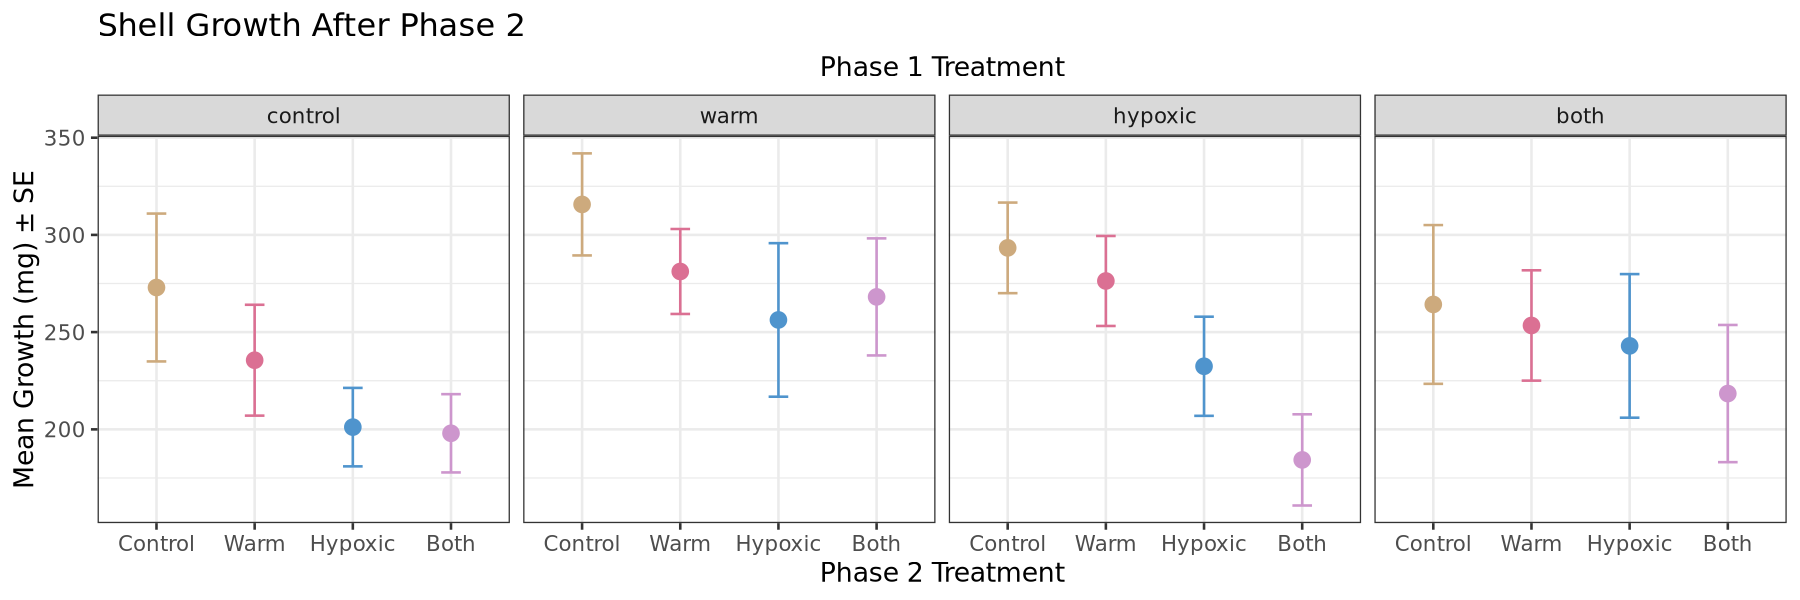

In [39]:
options(repr.plot.height = 5, repr.plot.width = 15)

shell16_plot <- ggplot(shell16, aes(x = Phase2_treatment, y = mean_growth, color = Phase2_treatment)) +
# Plot means as points
geom_point(size = 4, position = position_dodge(0.9)) + 
 # Error bars for SD
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
#scale_y_continuous(position = "right") +   # move y-axis to right 
facet_wrap(~Phase1_treatment, nrow = 1) +
scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
scale_x_discrete(labels = stringr::str_to_title) +
guides(fill = 'none') +
labs(x = 'Phase 2 Treatment',
    y = 'Mean Growth (mg) ± SE',
    title = 'Shell Growth After Phase 2',
    subtitle = 'Phase 1 Treatment') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.subtitle = element_text(hjust = 0.5)
) 

shell16_plot

#### tissue

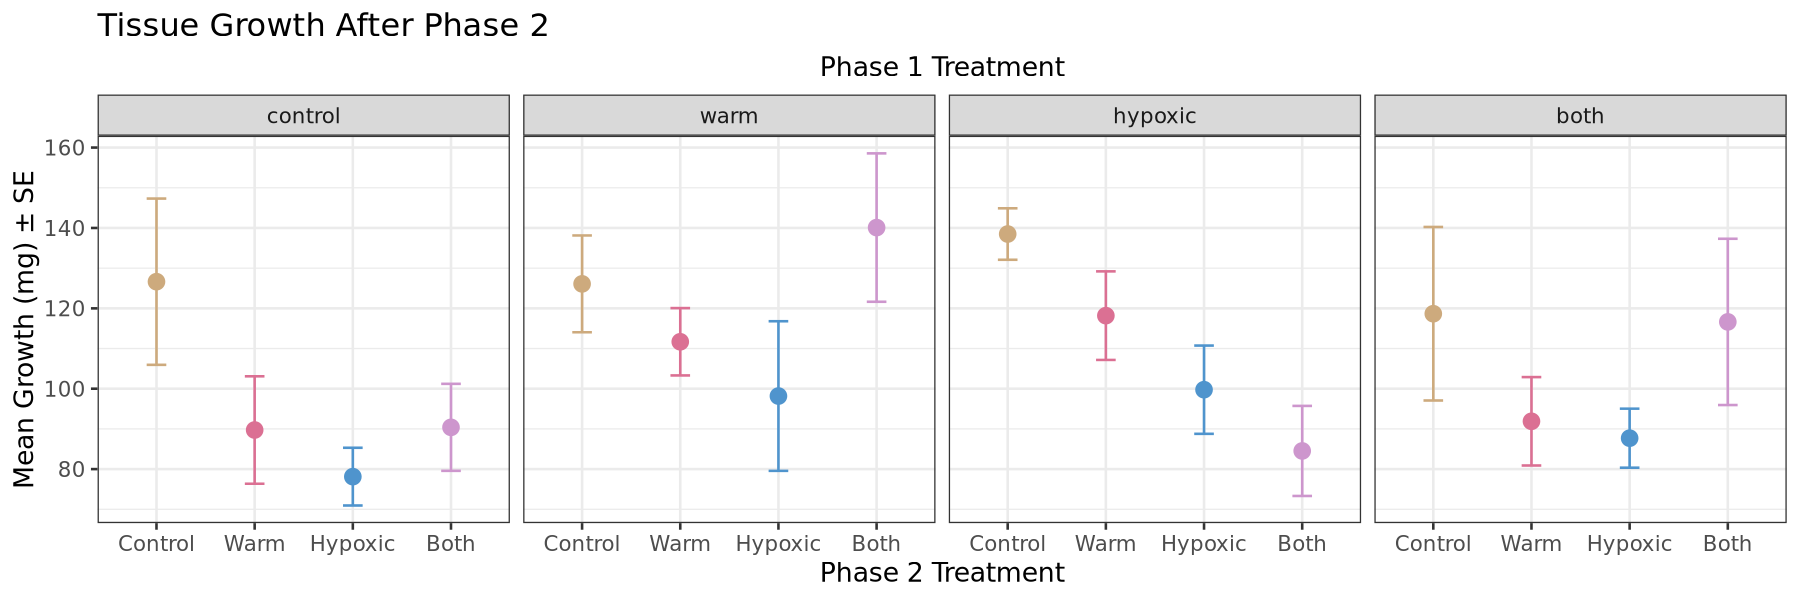

In [40]:
tissue16_plot <- ggplot(tissue16, aes(x = Phase2_treatment, y = mean_growth, color = Phase2_treatment)) +
# Plot means as points
geom_point(size = 4, position = position_dodge(0.9)) + 
 # Error bars for SD
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
#scale_y_continuous(position = "right") +   # move y-axis to right 
facet_wrap(~Phase1_treatment, nrow = 1) +
scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
scale_x_discrete(labels = stringr::str_to_title) +
guides(fill = 'none') +
labs(x = 'Phase 2 Treatment',
    y = 'Mean Growth (mg) ± SE',
    title = 'Tissue Growth After Phase 2',
    subtitle = 'Phase 1 Treatment') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.subtitle = element_text(hjust = 0.5)
) 

tissue16_plot

#### ratio

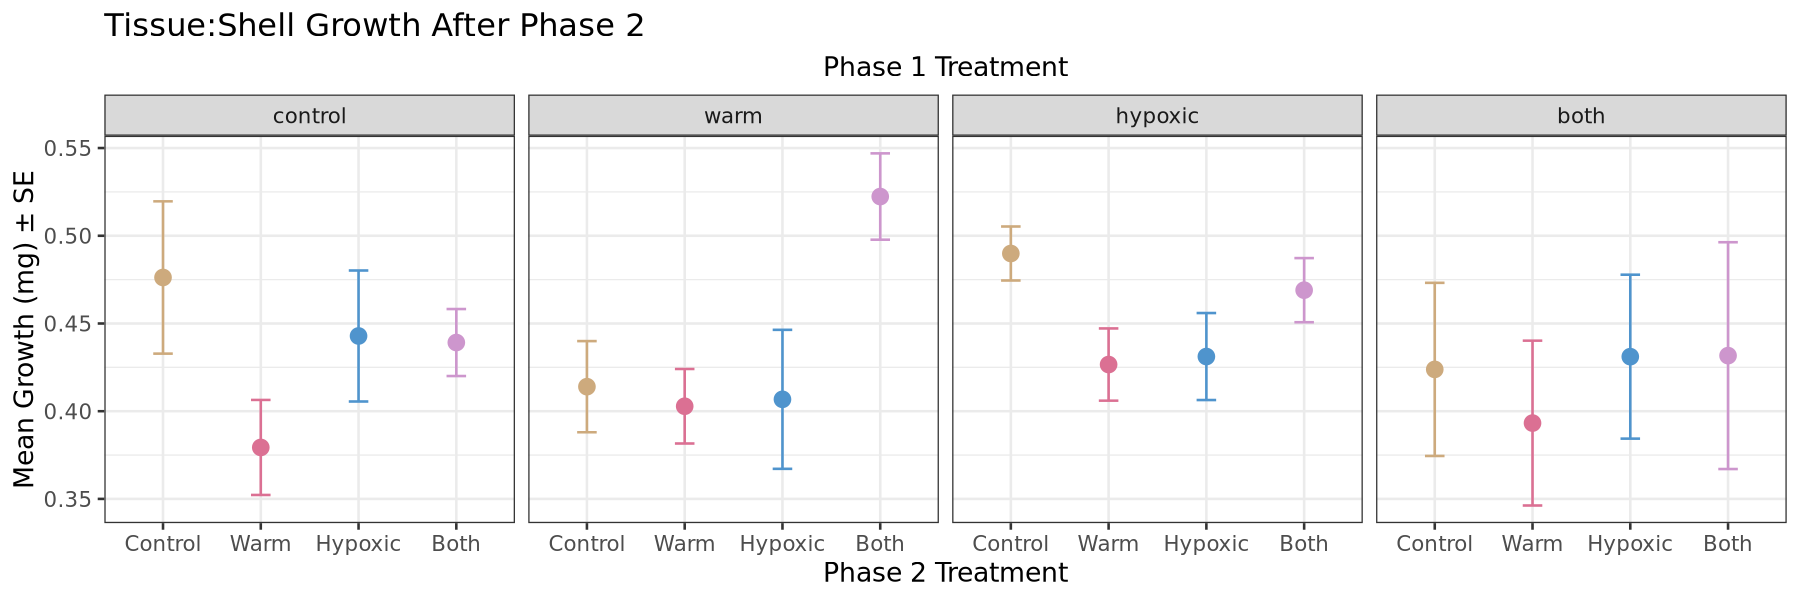

In [41]:
ratio16_plot <- ggplot(ratio16, aes(x = Phase2_treatment, y = mean_growth, color = Phase2_treatment)) +
# Plot means as points
geom_point(size = 4, position = position_dodge(0.9)) + 
 # Error bars for SD
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
#scale_y_continuous(position = "right") +   # move y-axis to right 
facet_wrap(~Phase1_treatment, nrow = 1) +
scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
scale_x_discrete(labels = stringr::str_to_title) +
guides(fill = 'none') +
labs(x = 'Phase 2 Treatment',
    y = 'Mean Growth (mg) ± SE',
    title = 'Tissue:Shell Growth After Phase 2',
    subtitle = 'Phase 1 Treatment') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.subtitle = element_text(hjust = 0.5)
) 

ratio16_plot

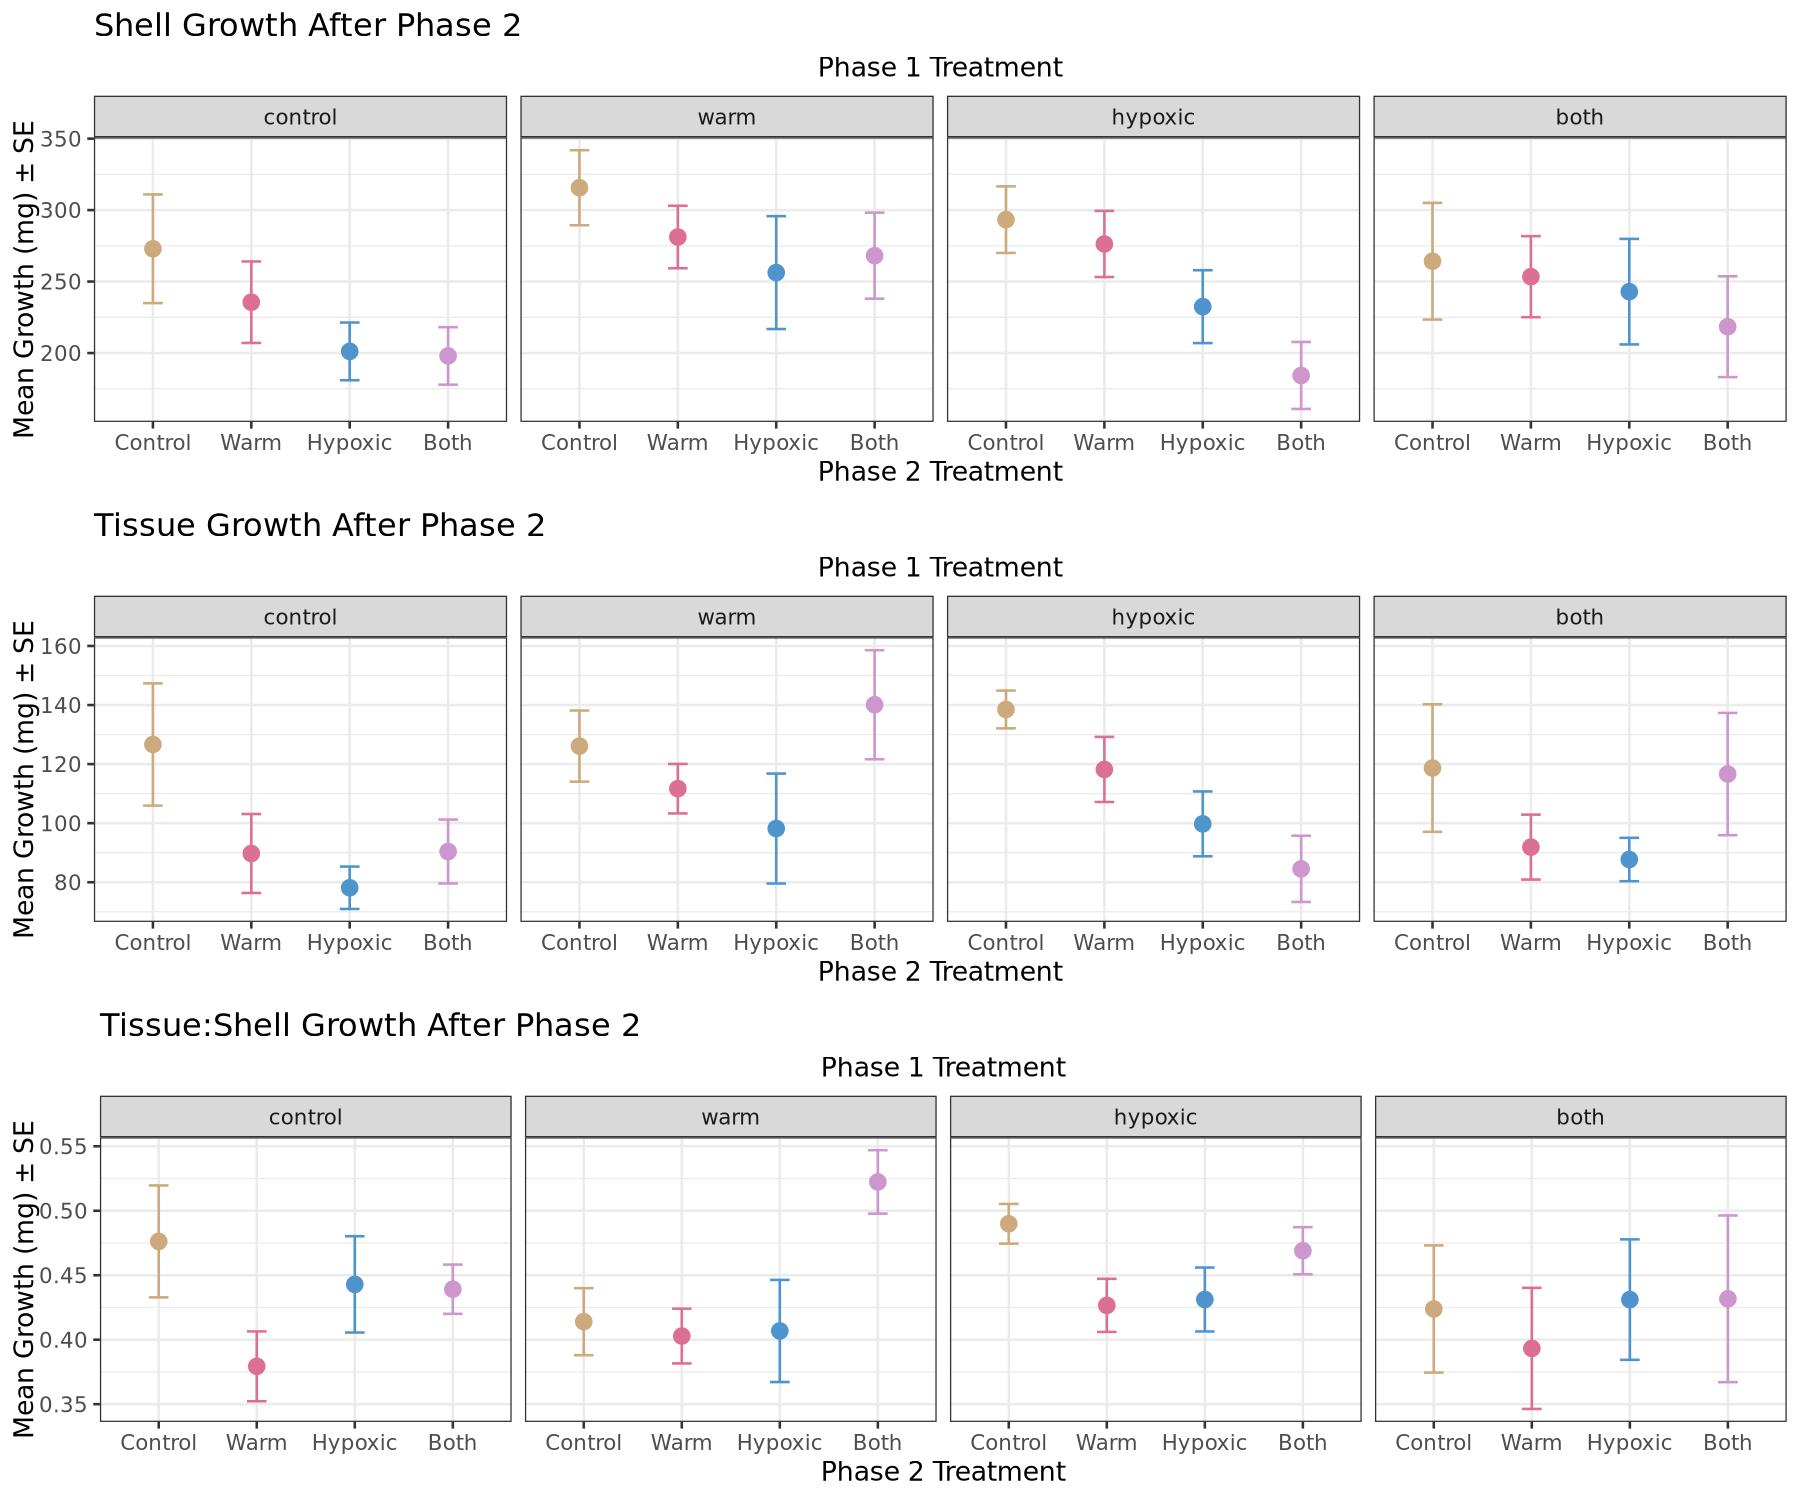

In [42]:
options(repr.plot.height = 12.5, repr.plot.width = 15) 

plot16 <- plot_grid(shell16_plot, tissue16_plot, ratio16_plot, nrow = 3)
plot16

# Phase 1 oysters

these only include oysters that were sequenced for RNA-seq

## 1. load CSVs

In [44]:
p1.growth.df <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/growth_phase1_weights.csv')

# add lead
p1.growth.df$Tag_num <- sprintf("%02d", p1.growth.df$Tag_num)

# need to convert sample names to be consistent with my naming convention
p1.growth.df$Sample <- paste0(substr(p1.growth.df$Phase_1_treat, 1, 1), p1.growth.df$Phase_1_rep, '_Nu_', p1.growth.df$Tag_color, p1.growth.df$Tag_num)

p1.growth.df <- p1.growth.df %>% dplyr::select(Sample, 
                            Phase_1_treat, 
                            Phase_1_temp, 
                            Phase_1_DO, 
                            Actual_tissue_growth_mg, 
                            Actual_shell_growth_mg, 
                            Ratio_tissue_shell_mg)

head(p1.growth.df)

,Sample,Phase_1_treat,Phase_1_temp,Phase_1_DO,Actual_tissue_growth_mg,Actual_shell_growth_mg,Ratio_tissue_shell_mg
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
1,B1_Nu_O01,Both,Warm,Hyp,21.92322,42.27678,0.518564091
2,B1_Nu_O02,Both,Warm,Hyp,42.34732,63.65268,0.665287306
3,B1_Nu_O03,Both,Warm,Hyp,27.91340,77.58660,0.359770888
4,B1_Nu_O04,Both,Warm,Hyp,148.21004,157.38996,0.941674043
5,B1_Nu_O05,Both,Warm,Hyp,-40.02418,-19.47582,2.055070339
6,B1_Nu_O06,Both,Warm,Hyp,117.50070,181.29930,0.64810344


In [45]:
p1wgcna <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/wgcna/outputs/p1.wgcna_metadata.csv')
head(p1wgcna)

,X,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Module,Eigengene
,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,1,B1_Nu_O03,both,warm,hypoxic,MEblack,-0.1384663
2,2,B2_Nu_O12,both,warm,hypoxic,MEblack,-0.1605248
3,3,B4_Nu_O32,both,warm,hypoxic,MEblack,-0.1047292
4,4,B5_Nu_O36,both,warm,hypoxic,MEblack,-0.1366478
5,5,B6_Nu_O47,both,warm,hypoxic,MEblack,-0.1180996
6,6,C1_Nu_W01,control,ambient,normoxic,MEblack,-0.1716039


pull only the samples that were sequenced and analyzed

In [49]:
p1.growth3 <- p1.growth.df[p1.growth.df$Sample %in% p1wgcna$Sample,]

dim(p1.growth3)
head(p1.growth3)

[1] 23  7

,Sample,Phase_1_treat,Phase_1_temp,Phase_1_DO,Actual_tissue_growth_mg,Actual_shell_growth_mg,Ratio_tissue_shell_mg
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
3,B1_Nu_O03,Both,Warm,Hyp,27.91340,77.58660,0.359770888
10,B2_Nu_O12,Both,Warm,Hyp,80.37700,150.42300,0.534339828
31,B4_Nu_O32,Both,Warm,Hyp,105.36056,145.03944,0.726426964
35,B5_Nu_O36,Both,Warm,Hyp,25.22362,32.77638,0.769566987
46,B6_Nu_O47,Both,Warm,Hyp,-12.30496,117.80496,-0.104451969
49,C1_Nu_W01,Cont,Ambient,Norm,136.95688,232.44312,0.589205996


In [50]:
unique(p1.growth3$Phase_1_treat)

[1] "Both" "Cont" "Hyp"  "Warm"

In [51]:
p1.growth <- p1.growth3

### set levels

In [63]:
# DO
p1.growth$Phase_1_DO <- factor(p1.growth$Phase_1_DO, 
                                        levels = c("Norm", "Hyp"))

# temp
p1.growth$Phase_1_temp <- factor(p1.growth$Phase_1_temp, 
                                        levels = c("Ambient", "Warm"))

# treatment interaction
p1.growth$Phase_1_treat <- factor(p1.growth$Phase_1_treat,
                                levels = c('Cont', 'Warm', 'Hyp', 'Both'))

In [64]:
p1.shell <- p1.growth.df %>%
select(Sample, Phase_1_treat, Phase_1_DO, Phase_1_temp, Actual_shell_growth_mg)
head(p1.shell)

,Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Actual_shell_growth_mg
,<chr>,<chr>,<chr>,<chr>,<dbl>
1,B1_Nu_O01,Both,Hyp,Warm,42.27678
2,B1_Nu_O02,Both,Hyp,Warm,63.65268
3,B1_Nu_O03,Both,Hyp,Warm,77.58660
4,B1_Nu_O04,Both,Hyp,Warm,157.38996
5,B1_Nu_O05,Both,Hyp,Warm,-19.47582
6,B1_Nu_O06,Both,Hyp,Warm,181.29930


In [65]:
p1.tissue <- p1.growth.df %>%
select(Sample, Phase_1_treat, Phase_1_DO, Phase_1_temp, Actual_tissue_growth_mg)
head(p1.tissue)

,Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Actual_tissue_growth_mg
,<chr>,<chr>,<chr>,<chr>,<dbl>
1,B1_Nu_O01,Both,Hyp,Warm,21.92322
2,B1_Nu_O02,Both,Hyp,Warm,42.34732
3,B1_Nu_O03,Both,Hyp,Warm,27.91340
4,B1_Nu_O04,Both,Hyp,Warm,148.21004
5,B1_Nu_O05,Both,Hyp,Warm,-40.02418
6,B1_Nu_O06,Both,Hyp,Warm,117.50070


## 2. plot

### Shell Growth

#### DO only

In [66]:
# get mean and SE for phase 1 DO
DOstats <- p1.shell %>%
  dplyr::group_by(Phase_1_DO) %>%
  mutate(
    mean_growth = mean(Actual_shell_growth_mg, na.rm = TRUE),
    se_growth = std.error(Actual_shell_growth_mg, na.rm = TRUE)) %>%
distinct(Phase_1_DO, .keep_all = TRUE)

DOstats

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Actual_shell_growth_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,42.27678,136.9443,10.15999
C1_Nu_W01,Cont,Norm,Ambient,232.44312,162.9352,12.88064


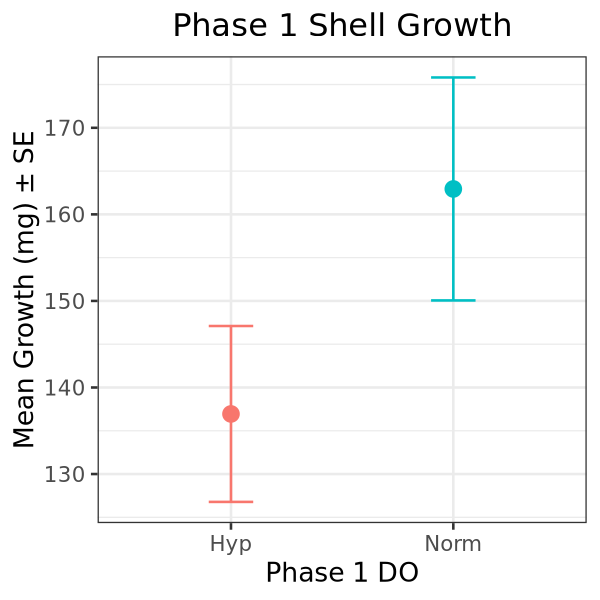

In [67]:
options(repr.plot.height = 5, repr.plot.width = 5)

ggplot(DOstats, aes(x = Phase_1_DO, y = mean_growth, color = Phase_1_DO)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 DO',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Shell Growth') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

#### Temp only

In [68]:
# get mean and SE for phase 1 DO
tempstats <- p1.shell %>%
  group_by(Phase_1_temp) %>%
  mutate(
    mean_growth = mean(Actual_shell_growth_mg, na.rm = TRUE),
    se_growth = std.error(Actual_shell_growth_mg, na.rm = TRUE)) %>%
distinct(Phase_1_temp, .keep_all = TRUE)

tempstats

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Actual_shell_growth_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,42.27678,137.8647,9.619634
C1_Nu_W01,Cont,Norm,Ambient,232.44312,162.0148,13.307322


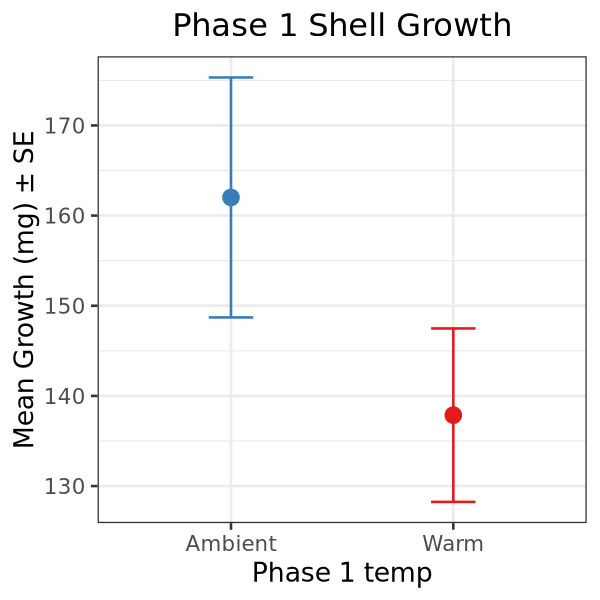

In [69]:
options(repr.plot.height = 5, repr.plot.width = 5)

ggplot(tempstats, aes(x = Phase_1_temp, y = mean_growth, color = Phase_1_temp)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 temp',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Shell Growth') +
scale_color_brewer(palette = 'Set1', direction = -1) +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

#### Interaction

#### DO only

In [70]:
# get mean and SE for phase 1 DO
interstats <- p1.shell %>%
  group_by(Phase_1_treat) %>%
  mutate(
    mean_growth = mean(Actual_shell_growth_mg, na.rm = TRUE),
    se_growth = std.error(Actual_shell_growth_mg, na.rm = TRUE)) %>%
distinct(Phase_1_treat, .keep_all = TRUE)

interstats

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Actual_shell_growth_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,42.27678,127.0415,14.41906
C1_Nu_W01,Cont,Norm,Ambient,232.44312,177.1825,22.38019
H1_Nu_B01,Hyp,Hyp,Ambient,218.35086,146.8472,14.32523
W1_Nu_G01,Warm,Norm,Warm,88.19538,148.6879,12.69619


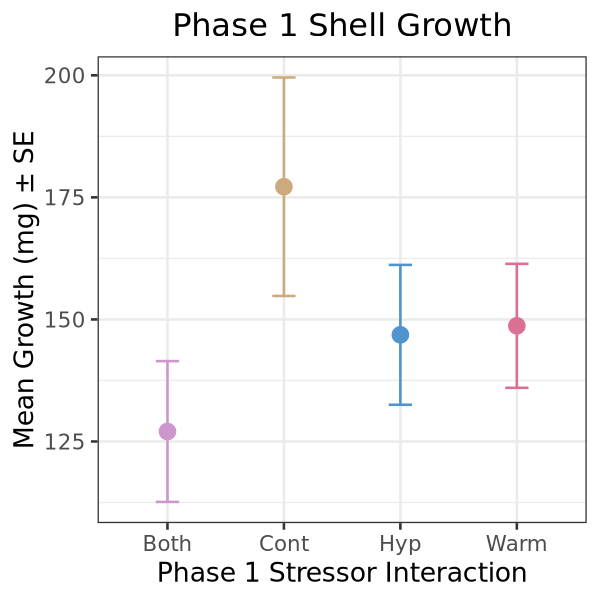

In [71]:
p1.shell <- ggplot(interstats, aes(x = Phase_1_treat, y = mean_growth, color = Phase_1_treat)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 Stressor Interaction',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Shell Growth') +
scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

p1.shell

doesn't appear to be a difference between warm and hypoxia, but a large difference between control and both

### Tissue Growth

#### DO only

In [72]:
# get mean and SE for phase 1 DO
DOstats.t <- p1.tissue %>%
  group_by(Phase_1_DO) %>%
  mutate(
    mean_growth = mean(Actual_tissue_growth_mg, na.rm = TRUE),
    se_growth = std.error(Actual_tissue_growth_mg, na.rm = TRUE)) %>%
distinct(Phase_1_DO, .keep_all = TRUE)

DOstats.t

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Actual_tissue_growth_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,21.92322,96.1609,8.238814
C1_Nu_W01,Cont,Norm,Ambient,136.95688,112.4353,10.159151


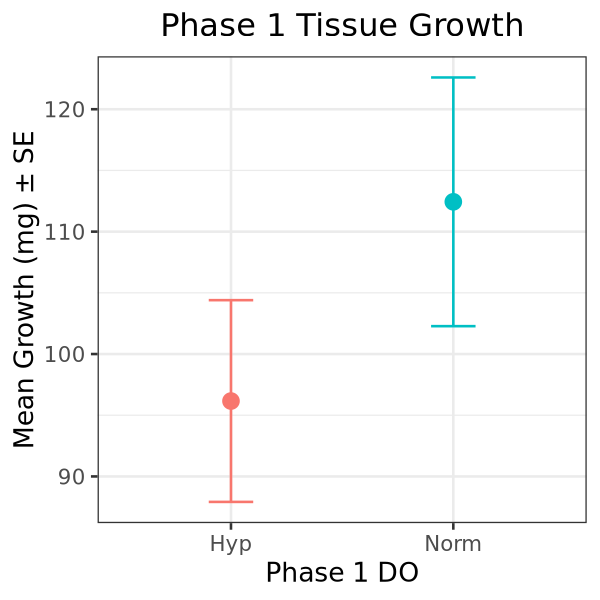

In [73]:
ggplot(DOstats.t, aes(x = Phase_1_DO, y = mean_growth, color = Phase_1_DO)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 DO',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Tissue Growth') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

#### Temp only

In [74]:
# get mean and SE for phase 1 DO
tempstats.t <- p1.tissue %>%
  group_by(Phase_1_temp) %>%
  mutate(
    mean_growth = mean(Actual_tissue_growth_mg, na.rm = TRUE),
    se_growth = std.error(Actual_tissue_growth_mg, na.rm = TRUE)) %>%
distinct(Phase_1_temp, .keep_all = TRUE)

tempstats.t

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Actual_tissue_growth_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,21.92322,91.1487,7.279223
C1_Nu_W01,Cont,Norm,Ambient,136.95688,117.2258,10.718182


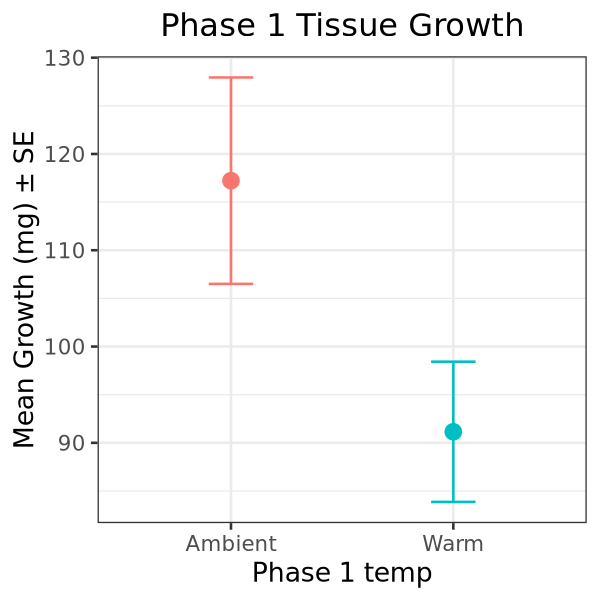

In [75]:
ggplot(tempstats.t, aes(x = Phase_1_temp, y = mean_growth, color = Phase_1_temp)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 temp',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Tissue Growth') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

#### Interaction

In [76]:
# get mean and SE for phase 1 DO
interstats.t <- p1.tissue %>%
  group_by(Phase_1_treat) %>%
  mutate(
    mean_growth = mean(Actual_tissue_growth_mg, na.rm = TRUE),
    se_growth = std.error(Actual_tissue_growth_mg, na.rm = TRUE)) %>%
distinct(Phase_1_treat, .keep_all = TRUE)

interstats.t

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Actual_tissue_growth_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,21.92322,80.85229,10.585390
C1_Nu_W01,Cont,Norm,Ambient,136.95688,122.98212,17.624374
H1_Nu_B01,Hyp,Hyp,Ambient,172.64914,111.46951,12.344134
W1_Nu_G01,Warm,Norm,Warm,24.50462,101.66417,9.857988


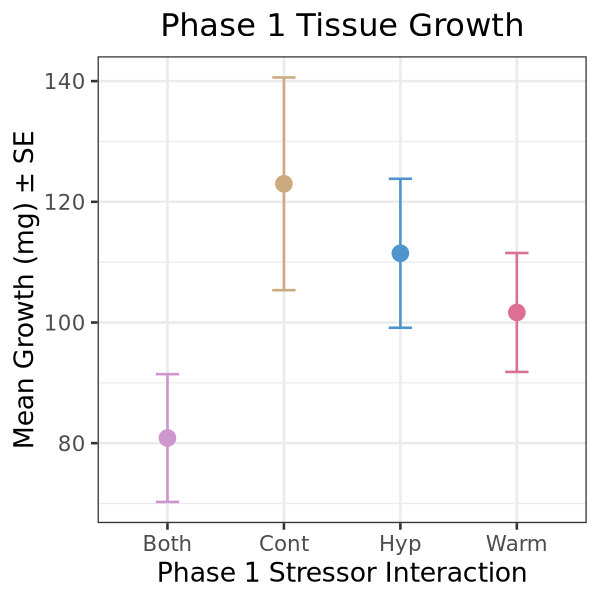

In [77]:
p1.t <- ggplot(interstats.t, aes(x = Phase_1_treat, y = mean_growth, color = Phase_1_treat)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 Stressor Interaction',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Tissue Growth') +
scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

p1.t

### Ratio T:S

In [81]:
p1.ts <- p1.growth.df %>%
select(Sample, Phase_1_treat, Phase_1_DO, Phase_1_temp, Ratio_tissue_shell_mg) %>%
filter(Ratio_tissue_shell_mg > 0)

p1.ts$Ratio_tissue_shell_mg <- as.numeric(p1.ts$ Ratio_tissue_shell_mg)
head(p1.ts)

,Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Ratio_tissue_shell_mg
,<chr>,<chr>,<chr>,<chr>,<dbl>
1,B1_Nu_O01,Both,Hyp,Warm,0.5185641
2,B1_Nu_O02,Both,Hyp,Warm,0.6652873
3,B1_Nu_O03,Both,Hyp,Warm,0.3597709
4,B1_Nu_O04,Both,Hyp,Warm,0.9416740
5,B1_Nu_O05,Both,Hyp,Warm,2.0550703
6,B1_Nu_O06,Both,Hyp,Warm,0.6481034


#### DO only

In [82]:
# get mean and SE for phase 1 DO
DOstats.t <- p1.ts %>%
  group_by(Phase_1_DO) %>%
  mutate(
    mean_growth = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_growth = std.error(Ratio_tissue_shell_mg, na.rm = TRUE)) %>%
distinct(Phase_1_DO, .keep_all = TRUE)

DOstats.t

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Ratio_tissue_shell_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,0.5185641,1.0380030,0.23201014
C1_Nu_W01,Cont,Norm,Ambient,0.5892060,0.7648685,0.04818261


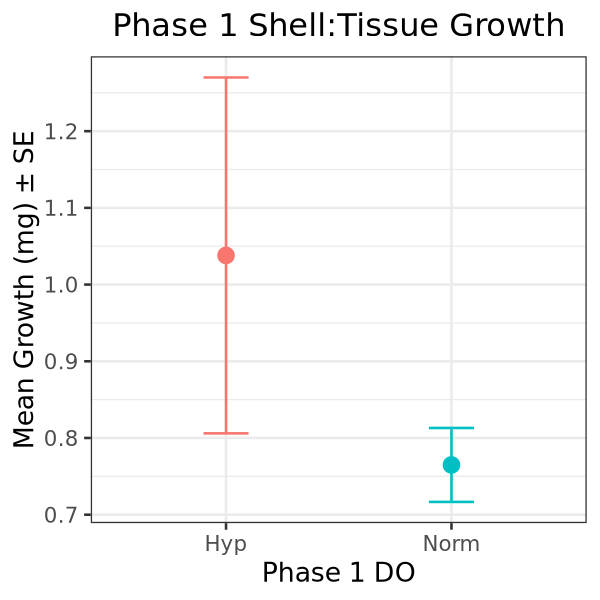

In [83]:
ggplot(DOstats.t, aes(x = Phase_1_DO, y = mean_growth, color = Phase_1_DO)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 DO',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Shell:Tissue Growth') +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

#### Temp only

In [84]:
# get mean and SE for phase 1 DO
tempstats.t <- p1.ts %>%
  group_by(Phase_1_temp) %>%
  mutate(
    mean_growth = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_growth = std.error(Ratio_tissue_shell_mg, na.rm = TRUE)) %>%
distinct(Phase_1_temp, .keep_all = TRUE)

tempstats.t

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Ratio_tissue_shell_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,0.5185641,0.9611940,0.2362035
C1_Nu_W01,Cont,Norm,Ambient,0.5892060,0.8479432,0.0637279


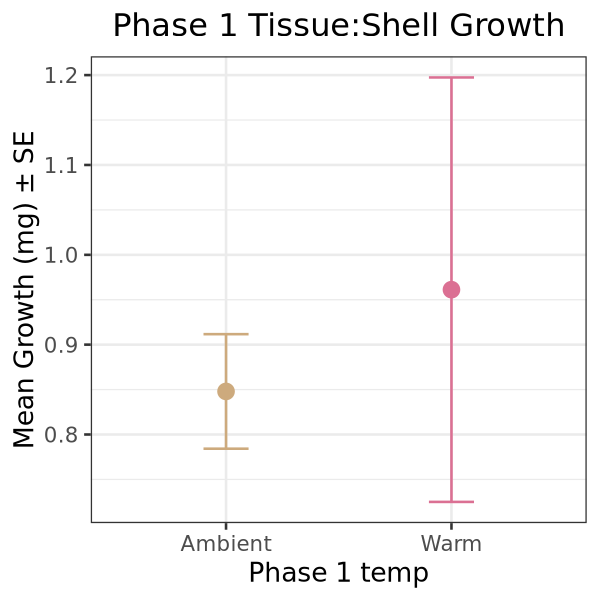

In [85]:
ggplot(tempstats.t, aes(x = Phase_1_temp, y = mean_growth, color = Phase_1_temp)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 temp',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Tissue:Shell Growth') +
scale_color_manual(values = c("Warm" = "palevioletred", "Ambient" = "burlywood3")) +

theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

#### Interaction

In [86]:
# get mean and SE for phase 1 DO
interstats.t <- p1.ts %>%
  group_by(Phase_1_treat) %>%
  mutate(
    mean_growth = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_growth = std.error(Ratio_tissue_shell_mg, na.rm = TRUE)) %>%
distinct(Phase_1_treat, .keep_all = TRUE)

interstats.t

Sample,Phase_1_treat,Phase_1_DO,Phase_1_temp,Ratio_tissue_shell_mg,mean_growth,se_growth
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1_Nu_O01,Both,Hyp,Warm,0.5185641,1.2312684,0.46518130
C1_Nu_W01,Cont,Norm,Ambient,0.5892060,0.8428853,0.08854750
H1_Nu_B01,Hyp,Hyp,Ambient,0.7906959,0.8527904,0.09242340
W1_Nu_G01,Warm,Norm,Warm,0.2778447,0.6851179,0.03346376


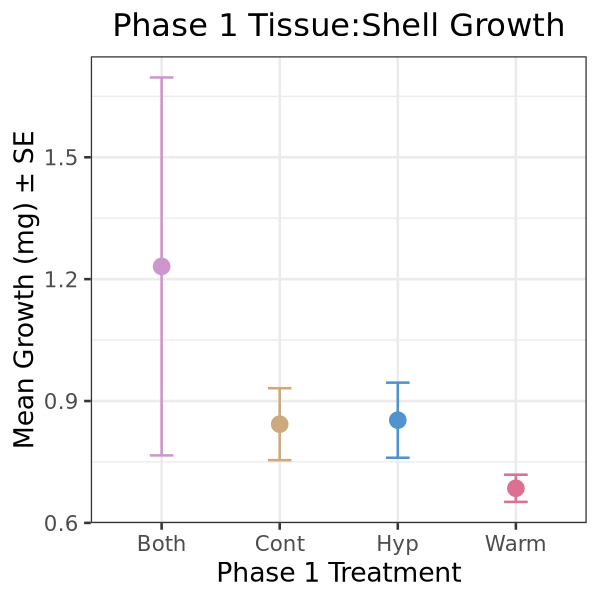

In [87]:
p1.ts <- ggplot(interstats.t, aes(x = Phase_1_treat, y = mean_growth, color = Phase_1_treat)) +
geom_point(size = 4, position = position_dodge(0.0)) +
geom_errorbar(aes(ymin = mean_growth - se_growth, ymax = mean_growth + se_growth), 
              width = 0.2, position = position_dodge(0.9)) +
guides(fill = 'none') +
labs(x = 'Phase 1 Treatment',
    y = 'Mean Growth (mg) ± SE',
    title = 'Phase 1 Tissue:Shell Growth') +
scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
theme_bw(base_size = 16) +
theme(legend.position = "none",
      plot.title = element_text(hjust = 0.5)
) 

p1.ts

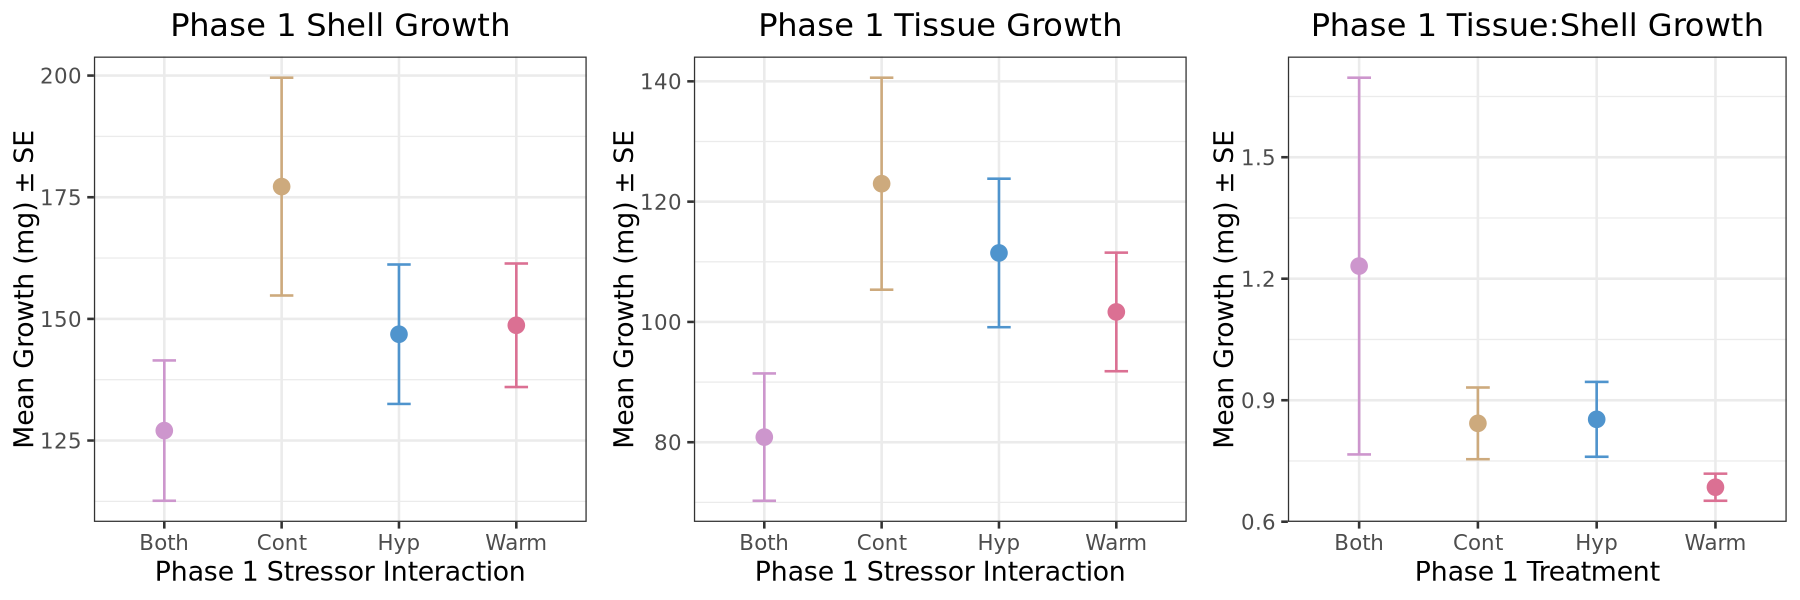

In [88]:
options(repr.plot.height = 5, repr.plot.width = 15)

plot1 <- plot_grid(p1.shell, p1.t, p1.ts, nrow = 1)
plot1

### violin plots

In [90]:
head(p1.growth)

,Sample,Phase_1_treat,Phase_1_temp,Phase_1_DO,Actual_tissue_growth_mg,Actual_shell_growth_mg,Ratio_tissue_shell_mg
,<chr>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<chr>
3,B1_Nu_O03,Both,Warm,Hyp,27.91340,77.58660,0.359770888
10,B2_Nu_O12,Both,Warm,Hyp,80.37700,150.42300,0.534339828
31,B4_Nu_O32,Both,Warm,Hyp,105.36056,145.03944,0.726426964
35,B5_Nu_O36,Both,Warm,Hyp,25.22362,32.77638,0.769566987
46,B6_Nu_O47,Both,Warm,Hyp,-12.30496,117.80496,-0.104451969
49,C1_Nu_W01,Cont,Ambient,Norm,136.95688,232.44312,0.589205996


In [92]:
# change to numeric instead of character
p1.growth$Ratio_tissue_shell_mg <- as.numeric(p1.growth$Ratio_tissue_shell_mg)

p1.growth_long <- p1.growth.df %>% 
select(Sample, Phase_1_treat, 'Shell Growth' = Actual_shell_growth_mg, 'Tissue Growth' = Actual_tissue_growth_mg) %>%
pivot_longer(cols = -c(Sample, Phase_1_treat),
             names_to = 'Growth_parameter',
             values_to = 'Growth_mg')

head(p1.growth_long)

Sample,Phase_1_treat,Growth_parameter,Growth_mg
<chr>,<chr>,<chr>,<dbl>
B1_Nu_O01,Both,Shell Growth,42.27678
B1_Nu_O01,Both,Tissue Growth,21.92322
B1_Nu_O02,Both,Shell Growth,63.65268
B1_Nu_O02,Both,Tissue Growth,42.34732
B1_Nu_O03,Both,Shell Growth,77.58660
B1_Nu_O03,Both,Tissue Growth,27.91340


In [93]:
head(p1.growth_long)

Sample,Phase_1_treat,Growth_parameter,Growth_mg
<chr>,<chr>,<chr>,<dbl>
B1_Nu_O01,Both,Shell Growth,42.27678
B1_Nu_O01,Both,Tissue Growth,21.92322
B1_Nu_O02,Both,Shell Growth,63.65268
B1_Nu_O02,Both,Tissue Growth,42.34732
B1_Nu_O03,Both,Shell Growth,77.58660
B1_Nu_O03,Both,Tissue Growth,27.91340


In [94]:
unique(p1.growth_long$Phase_1_treat)

[1] "Both" "Cont" "Hyp"  "Warm"

In [95]:
options(repr.plot.width = 12.5, repr.plot.height = 7.5)

#p1.growth_long$Phase_1_treat <- fct_relevel(p1.growth_long$Phase_1_treat, "Warm", after = 2)

p1.growth_long$Phase_1_treat <- factor(p1.growth_long$Phase_1_treat, levels = c('Cont', 'Hyp', 'Warm', 'Both'),
                                       labels = c('Control', 'Hypoxic', 'Warm', 'Both'))

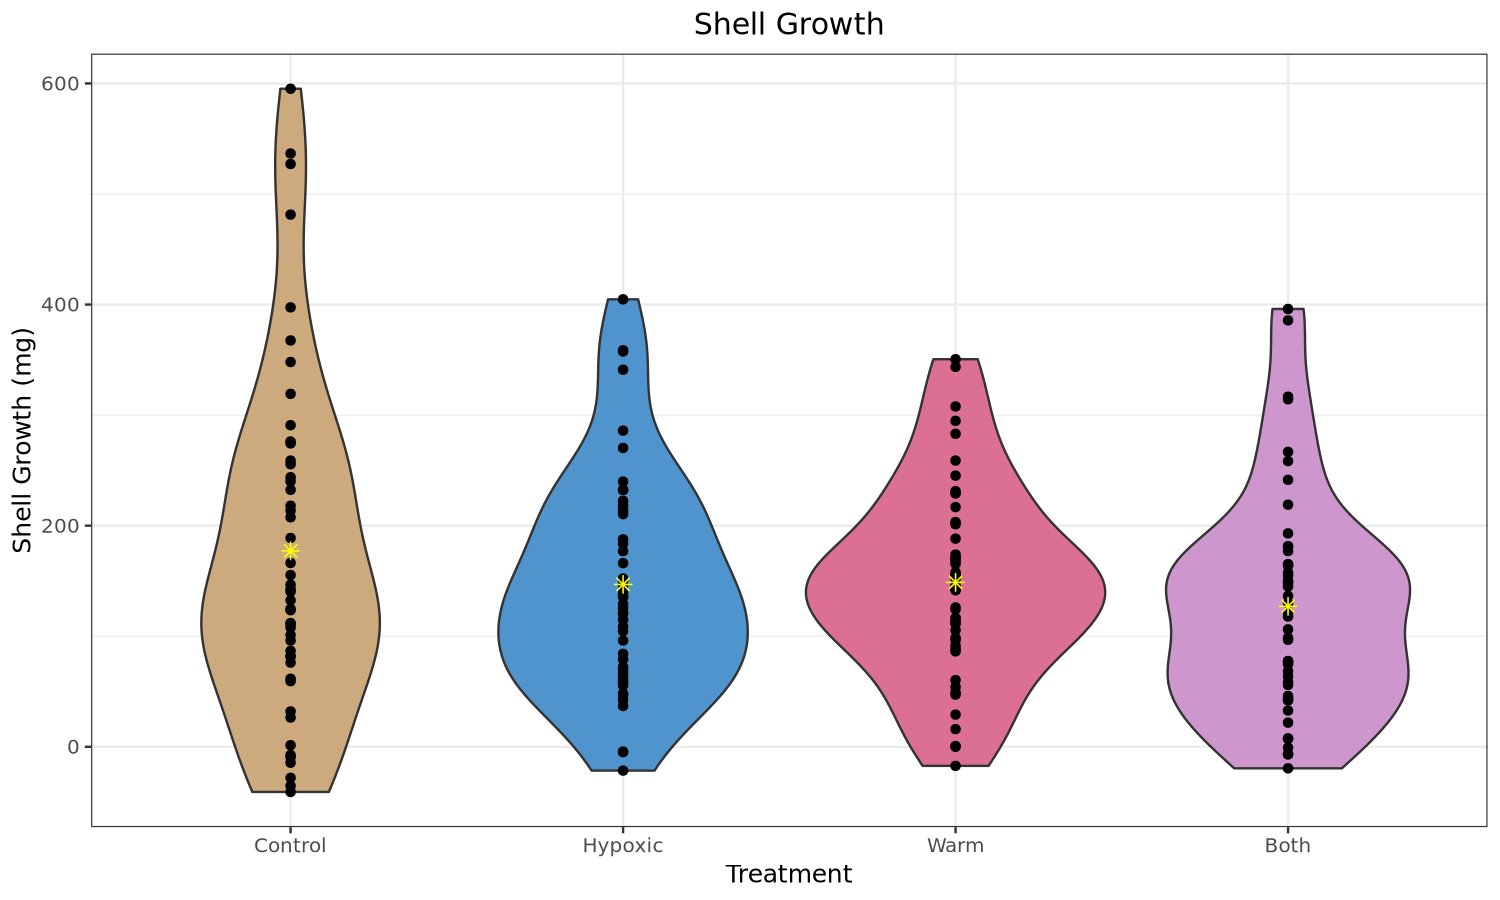

In [97]:
shell.plot <- ggplot(p1.growth_long %>% filter(Growth_parameter == 'Shell Growth'), aes(x = Phase_1_treat, y = Growth_mg, fill = Phase_1_treat)) +
geom_violin() +
geom_point() + 
# add point for mean
stat_summary(
    fun = "mean", 
    geom = "point", 
    shape = 8,      # asterick shape
    size = 3,        # Size of the point
    color = "yellow"  # Outline color
  ) +
scale_fill_manual(values = c("Hypoxic" = "steelblue3", "Warm" = "palevioletred", "Control" = "burlywood3", "Both" = "plum3")) +
#facet_wrap(~Growth_parameter, scales = 'free_y') +
guides(fill = 'none') +
theme_bw(base_size = 15) +
labs(x = 'Treatment',
     y = 'Shell Growth (mg)',
    title = 'Shell Growth') +
theme(plot.title = element_text(hjust = 0.5))

shell.plot

Warning message:
“Removed 1 row containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_summary()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


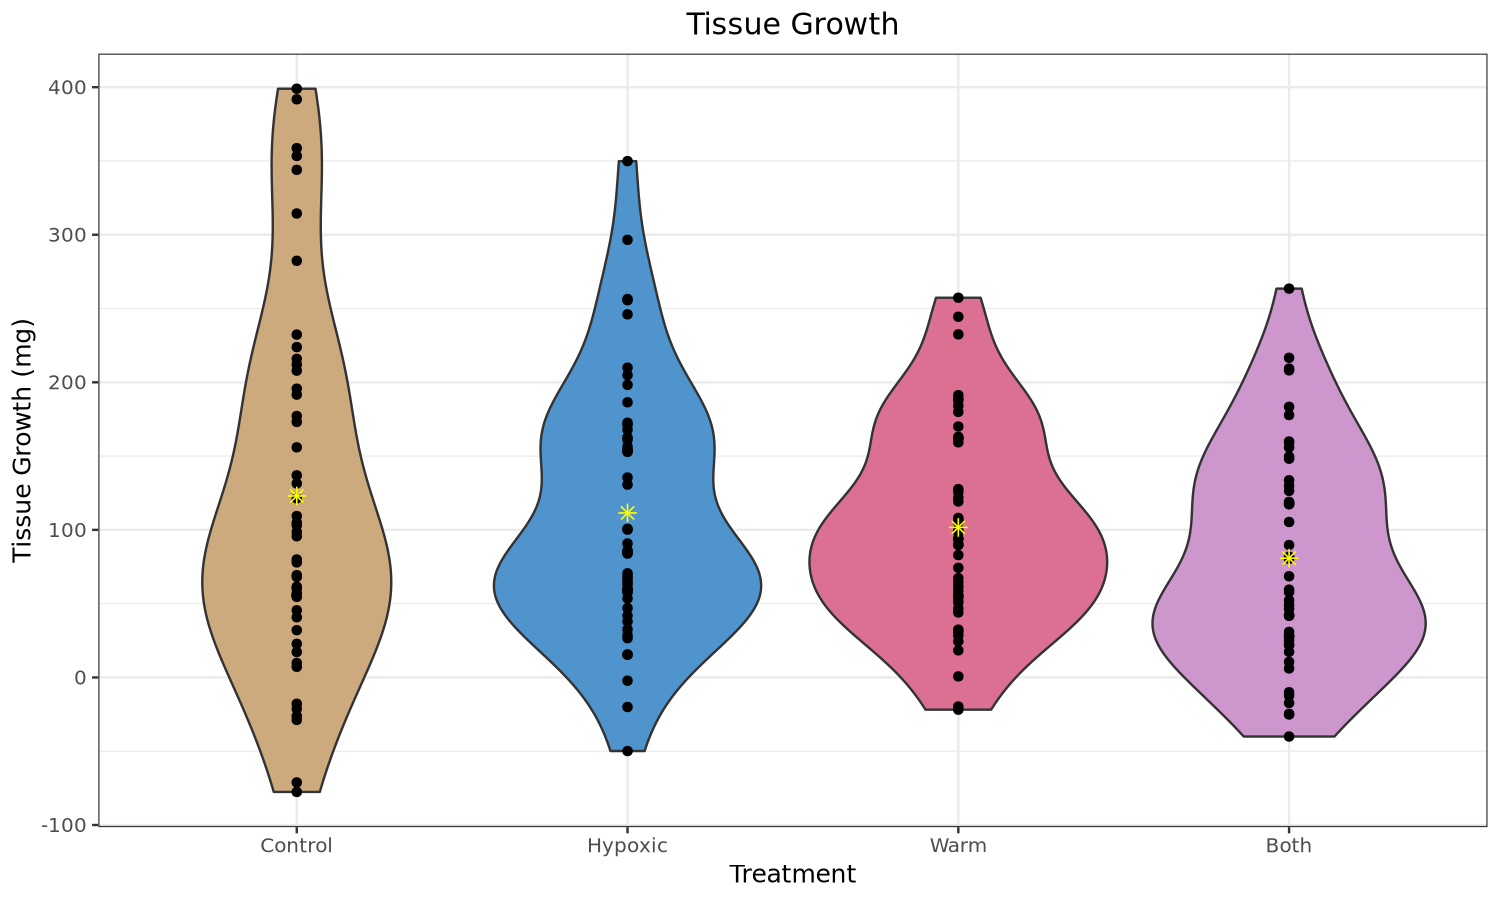

In [98]:
tissue.plot <- ggplot(p1.growth_long %>% filter(Growth_parameter == 'Tissue Growth'), aes(x = Phase_1_treat, y = Growth_mg, fill = Phase_1_treat)) +
geom_violin() +
geom_point() + 
# add point for mean
stat_summary(
    fun = "mean", 
    geom = "point", 
    shape = 8,      # asterick shape
    size = 3,        # Size of the point
    color = "yellow"  # Outline color
  ) +
scale_fill_manual(values = c("Hypoxic" = "steelblue3", "Warm" = "palevioletred", "Control" = "burlywood3", "Both" = "plum3")) +
#facet_wrap(~Growth_parameter, scales = 'free_y') +
guides(fill = 'none') +
theme_bw(base_size = 15) +
labs(x = 'Treatment',
     y = 'Tissue Growth (mg)',
    title = 'Tissue Growth') +
theme(plot.title = element_text(hjust = 0.5))

tissue.plot

Warning message:
“Removed 1 row containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_summary()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


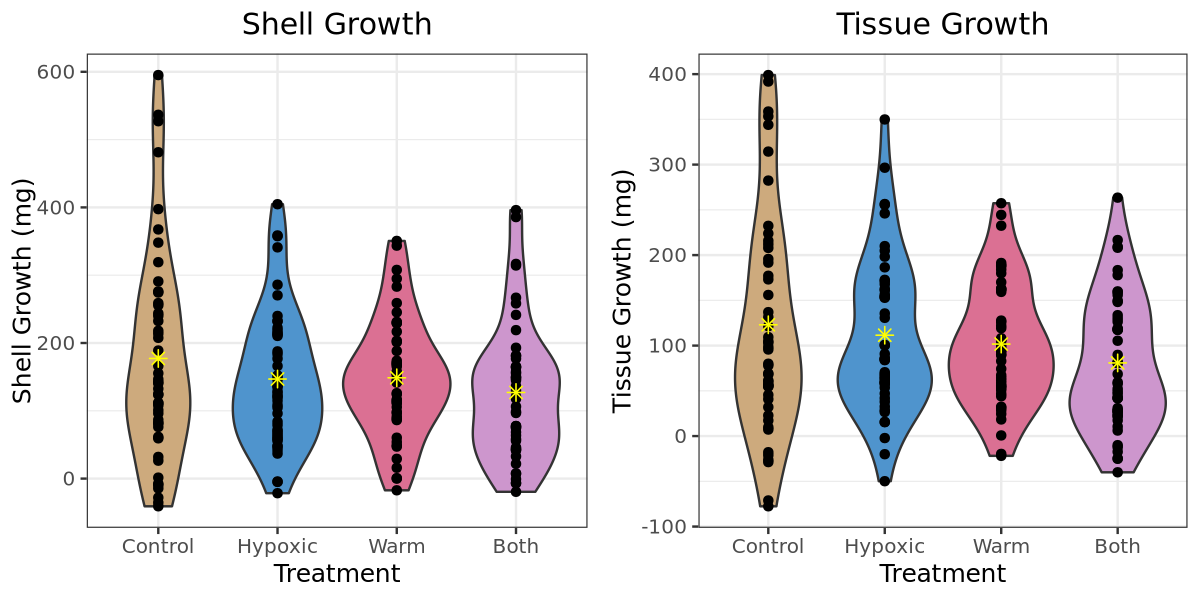

In [99]:
options(repr.plot.width = 10, repr.plot.height = 5)

plot_grid(shell.plot, tissue.plot)

In [100]:
options(repr.plot.width = 10, repr.plot.height = 10)

# Two-way ANOVA for the interaction itself (report this separately)
res.aov <- anova_test(p1.shell.df, Growth_mg ~ Phase1_temp * Phase1_DO)
res.aov

# Pairwise comparisons across all temp x DO cells
stat_test <- p1.shell.df %>%
  tukey_hsd(Growth_mg ~ Phase_1_treat) %>%
  add_significance("p.adj") %>%
  add_xy_position(data = p1.shell.df, x = "Phase_1_treat", step.increase = 0.1)

shell.stat.plot <- ggplot(p1.shell.df, aes(x = Phase_1_treat, y = Growth_mg, fill = Phase_1_treat)) +
  geom_violin() +
geom_point() +
stat_summary(
    fun = "mean", 
    geom = "point", 
    shape = 8,      # asterick shape
    size = 3,        # Size of the point
    color = "yellow"  # Outline color
  ) +
  stat_pvalue_manual(
    stat_test,
    label = "p.adj.signif",
    hide.ns = FALSE,
    tip.length = 0.01,
    inherit.aes = FALSE
  ) +
scale_fill_manual(values = c("Hypoxic" = "steelblue3", "Warm" = "palevioletred", "Control" = "burlywood3", "Both" = "plum3")) +
guides(fill = 'none') +
theme_bw(base_size = 15) +
labs(x = 'Treatment',
     y = 'Shell Growth (mg)',
    title = 'Shell Growth',
     subtitle = get_test_label(res.aov, detailed = TRUE)) +
theme(plot.title = element_text(hjust = 0.5))
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.1)))

shell.stat.plot

ERROR: Error: object 'p1.shell.df' not found


In [101]:
options(repr.plot.width = 10, repr.plot.height = 10)

# Two-way ANOVA for the interaction itself (report this separately)
res.aov <- anova_test(p1.tissue.df, Growth_mg ~ Phase1_temp * Phase1_DO)
res.aov

# Pairwise comparisons across all temp x DO cells
stat_test <- p1.tissue.df %>%
  tukey_hsd(Growth_mg ~ Phase_1_treat) %>%
  add_significance("p.adj") %>%
  add_xy_position(data = p1.tissue.df, x = "Phase_1_treat", step.increase = 0.1)

tissue.stat.plot <- ggplot(p1.tissue.df, aes(x = Phase_1_treat, y = Growth_mg, fill = Phase_1_treat)) +
  geom_violin() +
geom_point() +
stat_summary(
    fun = "mean", 
    geom = "point", 
    shape = 8,      # asterick shape
    size = 3,        # Size of the point
    color = "yellow"  # Outline color
  ) +
  stat_pvalue_manual(
    stat_test,
    label = "p.adj.signif",
    hide.ns = FALSE,
    tip.length = 0.01,
    inherit.aes = FALSE
  ) +
scale_fill_manual(values = c("Hypoxic" = "steelblue3", "Warm" = "palevioletred", "Control" = "burlywood3", "Both" = "plum3")) +
guides(fill = 'none') +
theme_bw(base_size = 15) +
labs(x = 'Treatment',
     y = 'Tissue Growth (mg)',
    title = 'Tissue Growth',
     subtitle = get_test_label(res.aov, detailed = TRUE)) +
theme(plot.title = element_text(hjust = 0.5))
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.1)))

tissue.stat.plot

ERROR: Error: object 'p1.tissue.df' not found


In [ ]:
options(repr.plot.width = 15, repr.plot.height = 7.5)

plot_grid(shell.stat.plot, tissue.stat.plot)

## 3. stat testing

#### shell growth

In [108]:
p1.shell.df <- p1.growth_long %>% filter(Growth_parameter == 'Shell Growth') %>%
mutate(Phase1_temp = case_when(
    Phase_1_treat %in% c('Both', 'Warm') ~ 'Warm',
    TRUE ~ 'Ambient'),
      Phase1_DO = case_when(
          Phase_1_treat %in% c('Both', 'Hypoxic') ~ 'Hypoxic',
    TRUE ~ 'Normoxic')
      )

head(p1.shell.df)

Sample,Phase_1_treat,Growth_parameter,Growth_mg,Phase1_temp,Phase1_DO
<chr>,<fct>,<chr>,<dbl>,<chr>,<chr>
B1_Nu_O01,Both,Shell Growth,42.27678,Warm,Hypoxic
B1_Nu_O02,Both,Shell Growth,63.65268,Warm,Hypoxic
B1_Nu_O03,Both,Shell Growth,77.58660,Warm,Hypoxic
B1_Nu_O04,Both,Shell Growth,157.38996,Warm,Hypoxic
B1_Nu_O05,Both,Shell Growth,-19.47582,Warm,Hypoxic
B1_Nu_O06,Both,Shell Growth,181.29930,Warm,Hypoxic


In [109]:
shell.anova <- aov(Growth_mg ~ Phase1_temp * Phase1_DO, data = p1.shell.df)
summary(shell.anova)

                       Df  Sum Sq Mean Sq F value Pr(>F)
Phase1_temp             1   27995   27995   2.170  0.142
Phase1_DO               1   32425   32425   2.513  0.115
Phase1_temp:Phase1_DO   1     906     906   0.070  0.791
Residuals             188 2425623   12902               

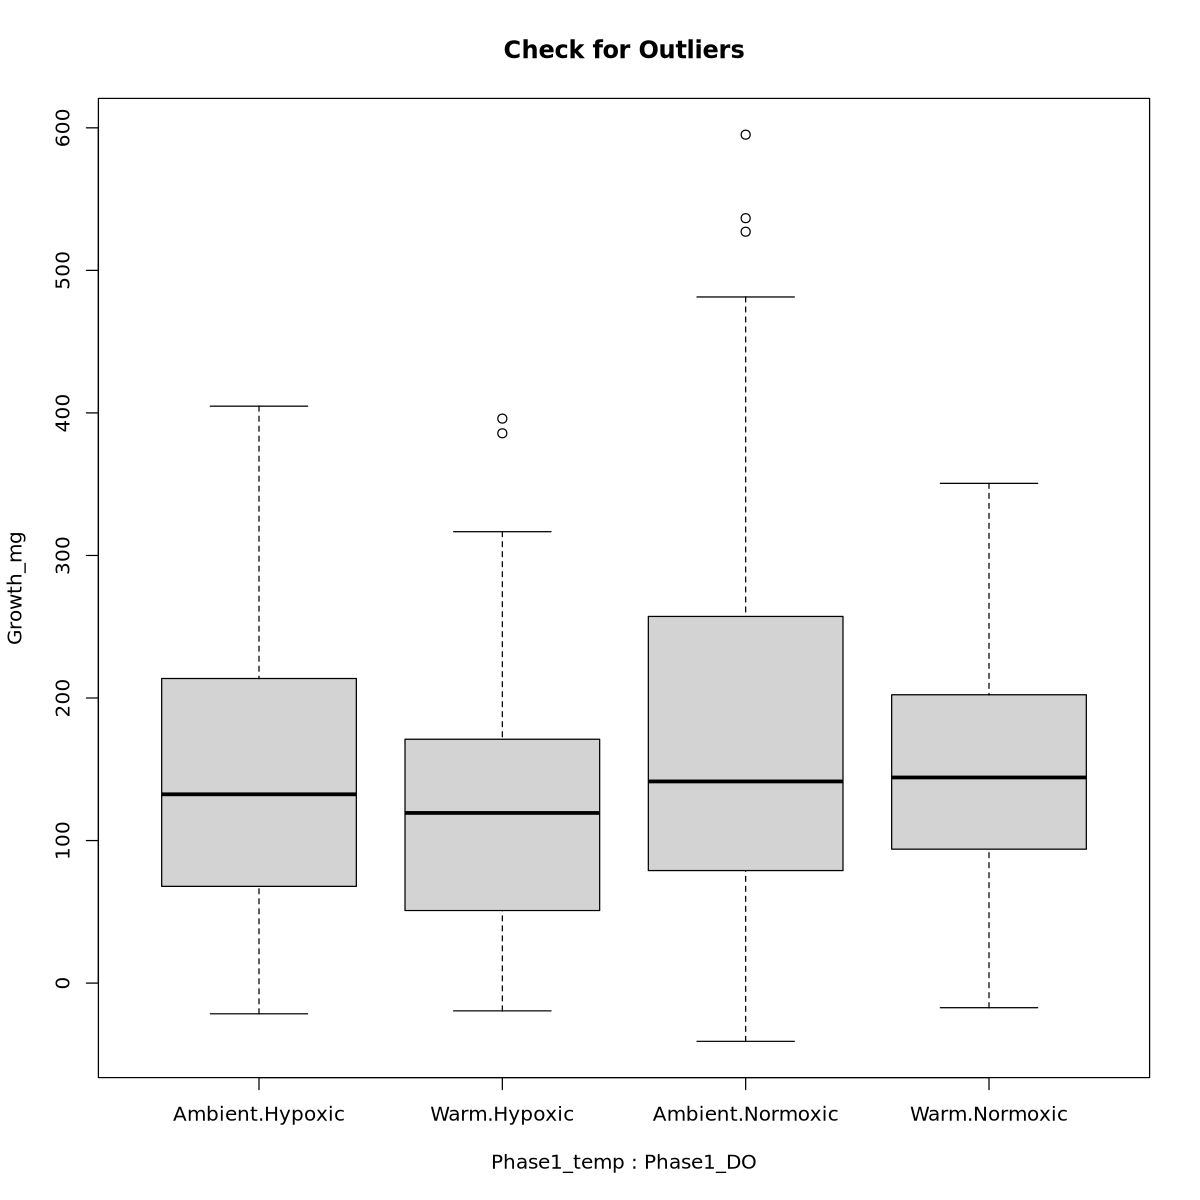

In [110]:
boxplot(Growth_mg ~ Phase1_temp * Phase1_DO, data = p1.shell.df, main = "Check for Outliers")


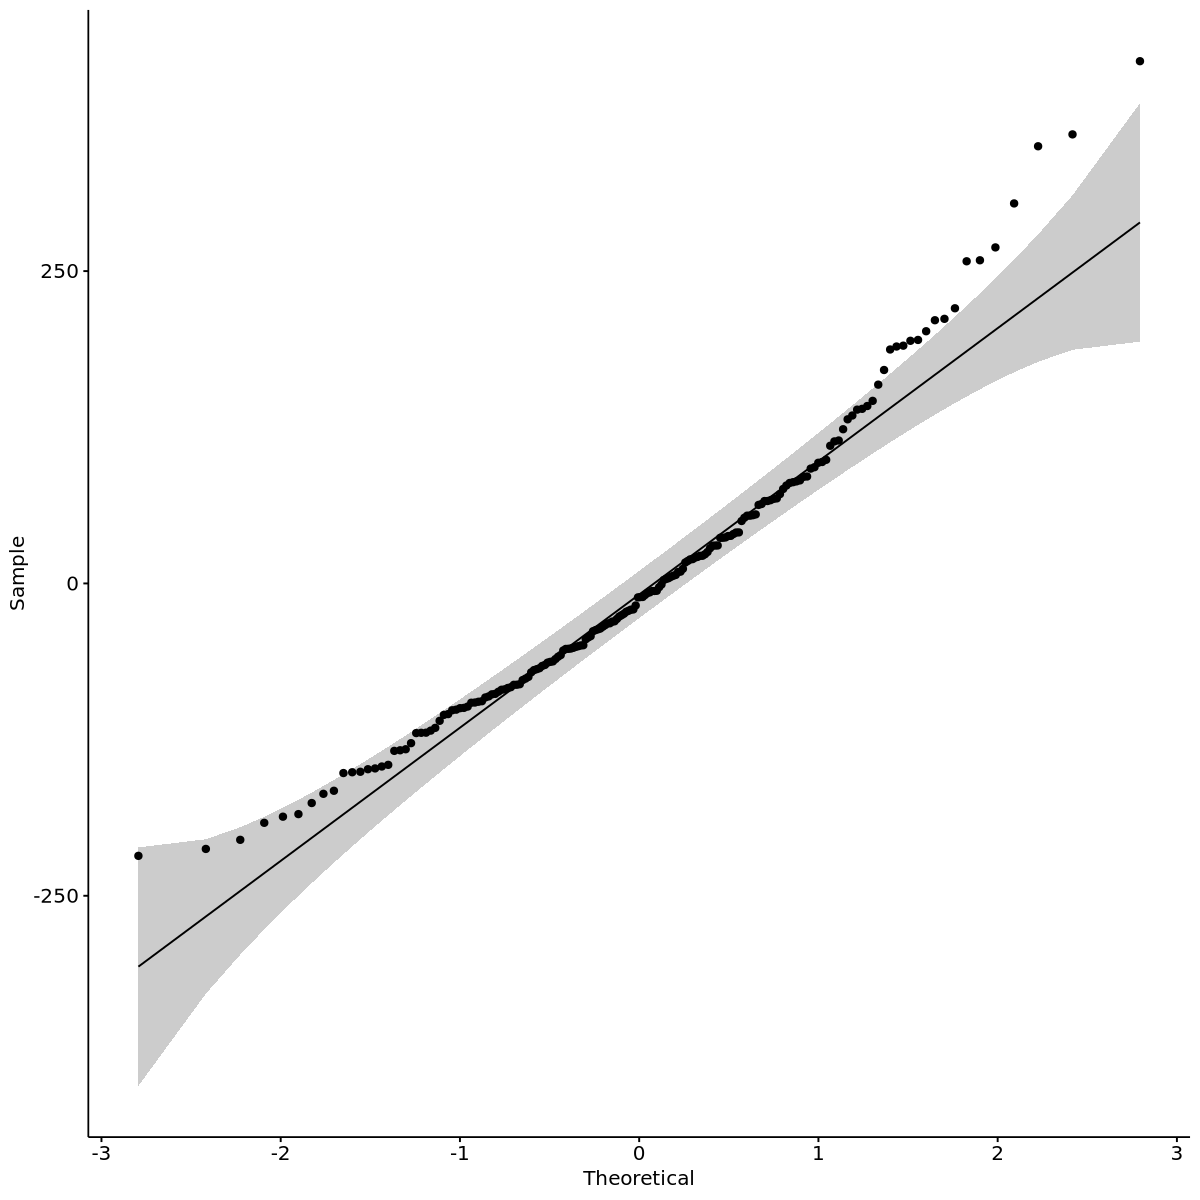

In [111]:
ggqqplot(residuals(shell.anova))

points fall closely on this line

In [112]:
# normality
shapiro.test(residuals(shell.anova))


	Shapiro-Wilk normality test

data:  residuals(shell.anova)
W = 0.95991, p-value = 2.846e-05


null hypothesis (assumes normality) stands with non-significant pvalue

In [113]:
# homogeneity of variance
leveneTest(Growth_mg ~ Phase1_temp * Phase1_DO, data = p1.shell.df)

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,3,4.337986,0.005543814
,188,NA,NA


confirms equal variances with non-significant pvalue

#### tissue growth

In [114]:
p1.tissue.df <- p1.growth_long %>% filter(Growth_parameter == 'Tissue Growth') %>%
mutate(Phase1_temp = case_when(
    Phase_1_treat %in% c('Both', 'Warm') ~ 'Warm',
    TRUE ~ 'Ambient'),
      Phase1_DO = case_when(
          Phase_1_treat %in% c('Both', 'Hypoxic') ~ 'Hypoxic',
    TRUE ~ 'Normoxic')
      )

head(p1.tissue.df)

Sample,Phase_1_treat,Growth_parameter,Growth_mg,Phase1_temp,Phase1_DO
<chr>,<fct>,<chr>,<dbl>,<chr>,<chr>
B1_Nu_O01,Both,Tissue Growth,21.92322,Warm,Hypoxic
B1_Nu_O02,Both,Tissue Growth,42.34732,Warm,Hypoxic
B1_Nu_O03,Both,Tissue Growth,27.91340,Warm,Hypoxic
B1_Nu_O04,Both,Tissue Growth,148.21004,Warm,Hypoxic
B1_Nu_O05,Both,Tissue Growth,-40.02418,Warm,Hypoxic
B1_Nu_O06,Both,Tissue Growth,117.50070,Warm,Hypoxic


In [115]:
tissue.anova <- aov(Growth_mg ~ Phase1_temp * Phase1_DO, data = p1.tissue.df)
summary(tissue.anova)

                       Df  Sum Sq Mean Sq F value Pr(>F)  
Phase1_temp             1   32470   32470   4.028 0.0462 *
Phase1_DO               1   12435   12435   1.543 0.2158  
Phase1_temp:Phase1_DO   1    1032    1032   0.128 0.7209  
Residuals             187 1507408    8061                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
1 observation deleted due to missingness

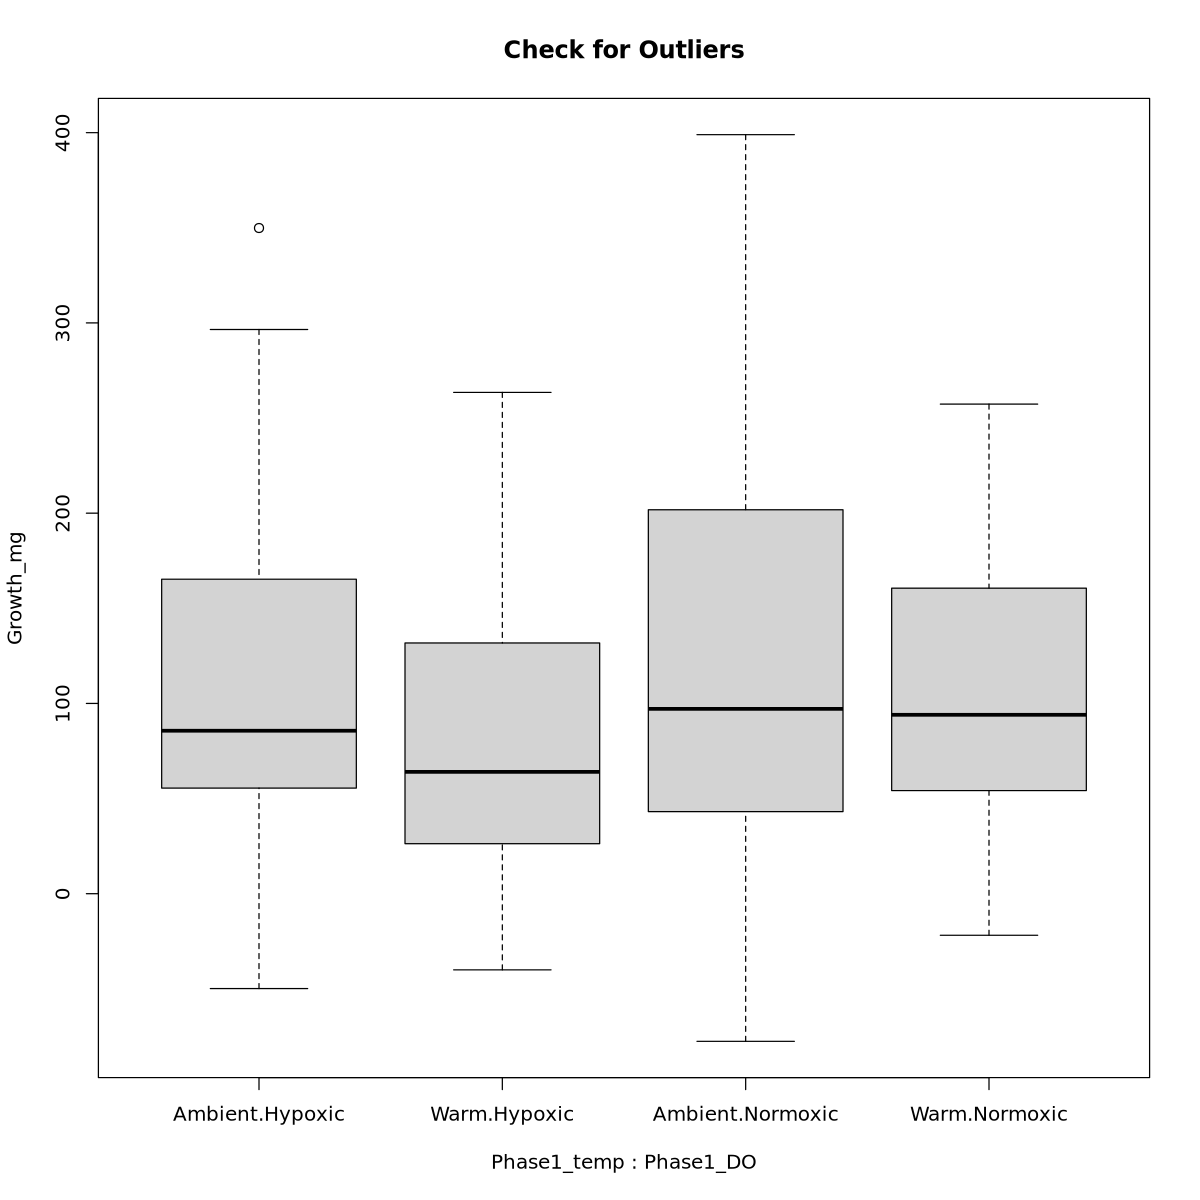

In [116]:
boxplot(Growth_mg ~ Phase1_temp * Phase1_DO, data = p1.tissue.df, main = "Check for Outliers")


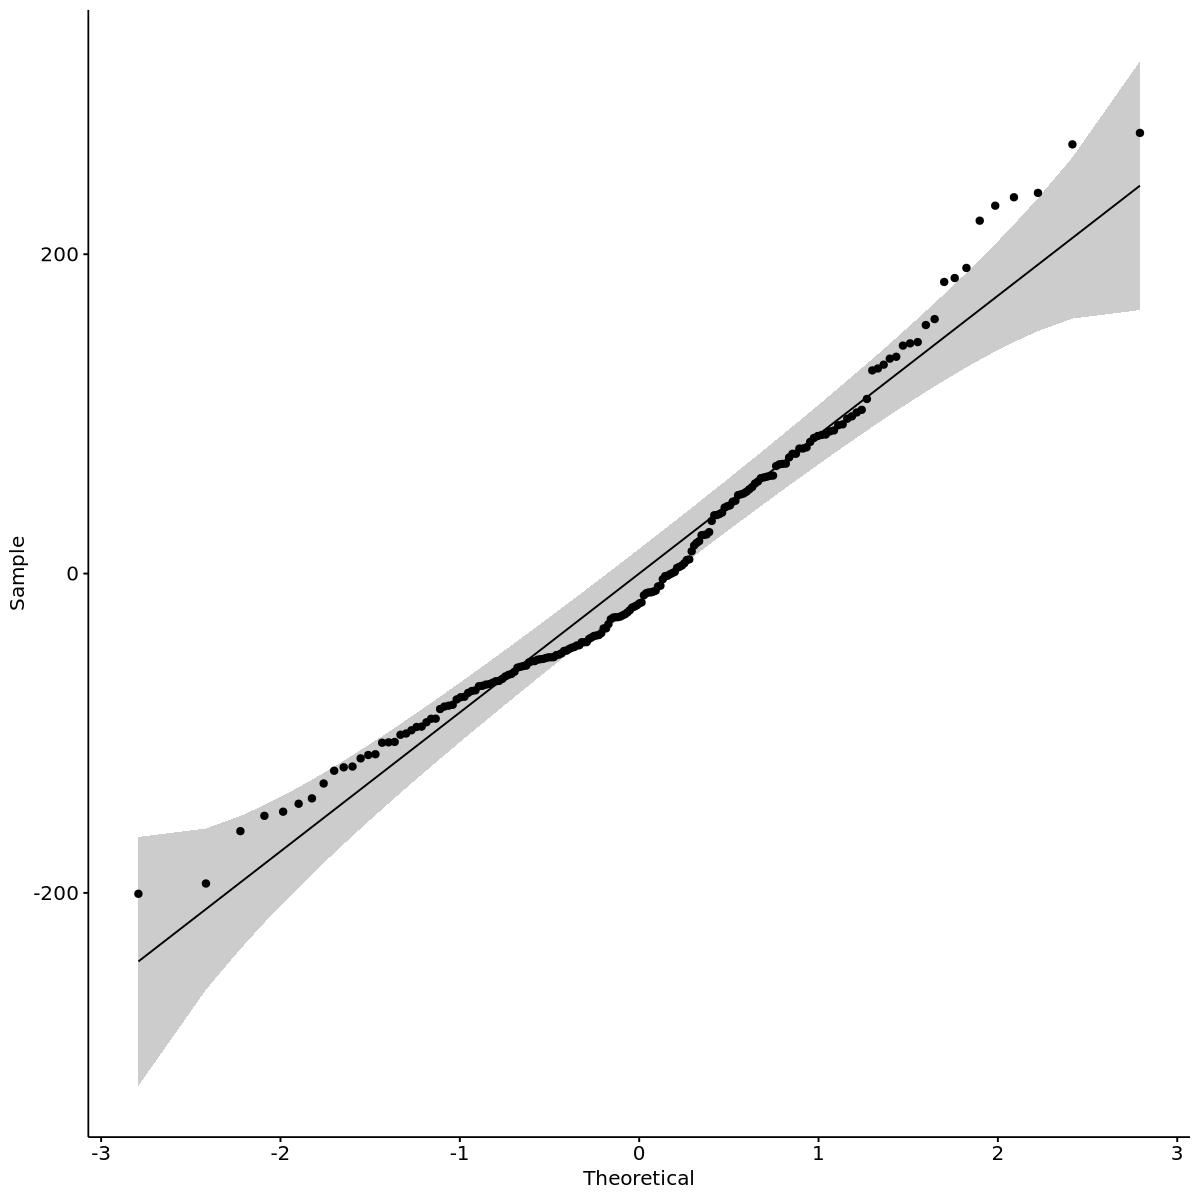

In [117]:
ggqqplot(residuals(tissue.anova))

points fall closely on this line

In [118]:
# normality
shapiro.test(residuals(tissue.anova))


	Shapiro-Wilk normality test

data:  residuals(tissue.anova)
W = 0.96762, p-value = 0.0002131


null hypothesis (assumes normality) stands with non-significant pvalue

In [119]:
# homogeneity of variance
leveneTest(Growth_mg ~ Phase1_temp * Phase1_DO, data = p1.tissue.df)

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,3,4.741197,0.003273688
,187,NA,NA


confirms equal variances with non-significant pvalue

#### ratio tissue:shell growth

In [120]:
head(p1.growth)

,Sample,Phase_1_treat,Phase_1_temp,Phase_1_DO,Actual_tissue_growth_mg,Actual_shell_growth_mg,Ratio_tissue_shell_mg
,<chr>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
3,B1_Nu_O03,Both,Warm,Hyp,27.91340,77.58660,0.3597709
10,B2_Nu_O12,Both,Warm,Hyp,80.37700,150.42300,0.5343398
31,B4_Nu_O32,Both,Warm,Hyp,105.36056,145.03944,0.7264270
35,B5_Nu_O36,Both,Warm,Hyp,25.22362,32.77638,0.7695670
46,B6_Nu_O47,Both,Warm,Hyp,-12.30496,117.80496,-0.1044520
49,C1_Nu_W01,Cont,Ambient,Norm,136.95688,232.44312,0.5892060


In [121]:
p1.ratio <- p1.growth %>% 
select(Sample, Phase_1_treat, Phase_1_temp, Phase_1_DO, Ratio_tissue_shell_mg)

head(p1.ratio)

,Sample,Phase_1_treat,Phase_1_temp,Phase_1_DO,Ratio_tissue_shell_mg
,<chr>,<fct>,<fct>,<fct>,<dbl>
3,B1_Nu_O03,Both,Warm,Hyp,0.3597709
10,B2_Nu_O12,Both,Warm,Hyp,0.5343398
31,B4_Nu_O32,Both,Warm,Hyp,0.7264270
35,B5_Nu_O36,Both,Warm,Hyp,0.7695670
46,B6_Nu_O47,Both,Warm,Hyp,-0.1044520
49,C1_Nu_W01,Cont,Ambient,Norm,0.5892060


In [122]:
ratio.anova <- aov(Ratio_tissue_shell_mg ~ Phase_1_temp * Phase_1_DO, data = p1.ratio)
summary(ratio.anova)

                        Df Sum Sq Mean Sq F value Pr(>F)
Phase_1_temp             1 0.0317 0.03165   0.614  0.443
Phase_1_DO               1 0.0087 0.00873   0.169  0.685
Phase_1_temp:Phase_1_DO  1 0.1302 0.13023   2.525  0.129
Residuals               19 0.9800 0.05158               

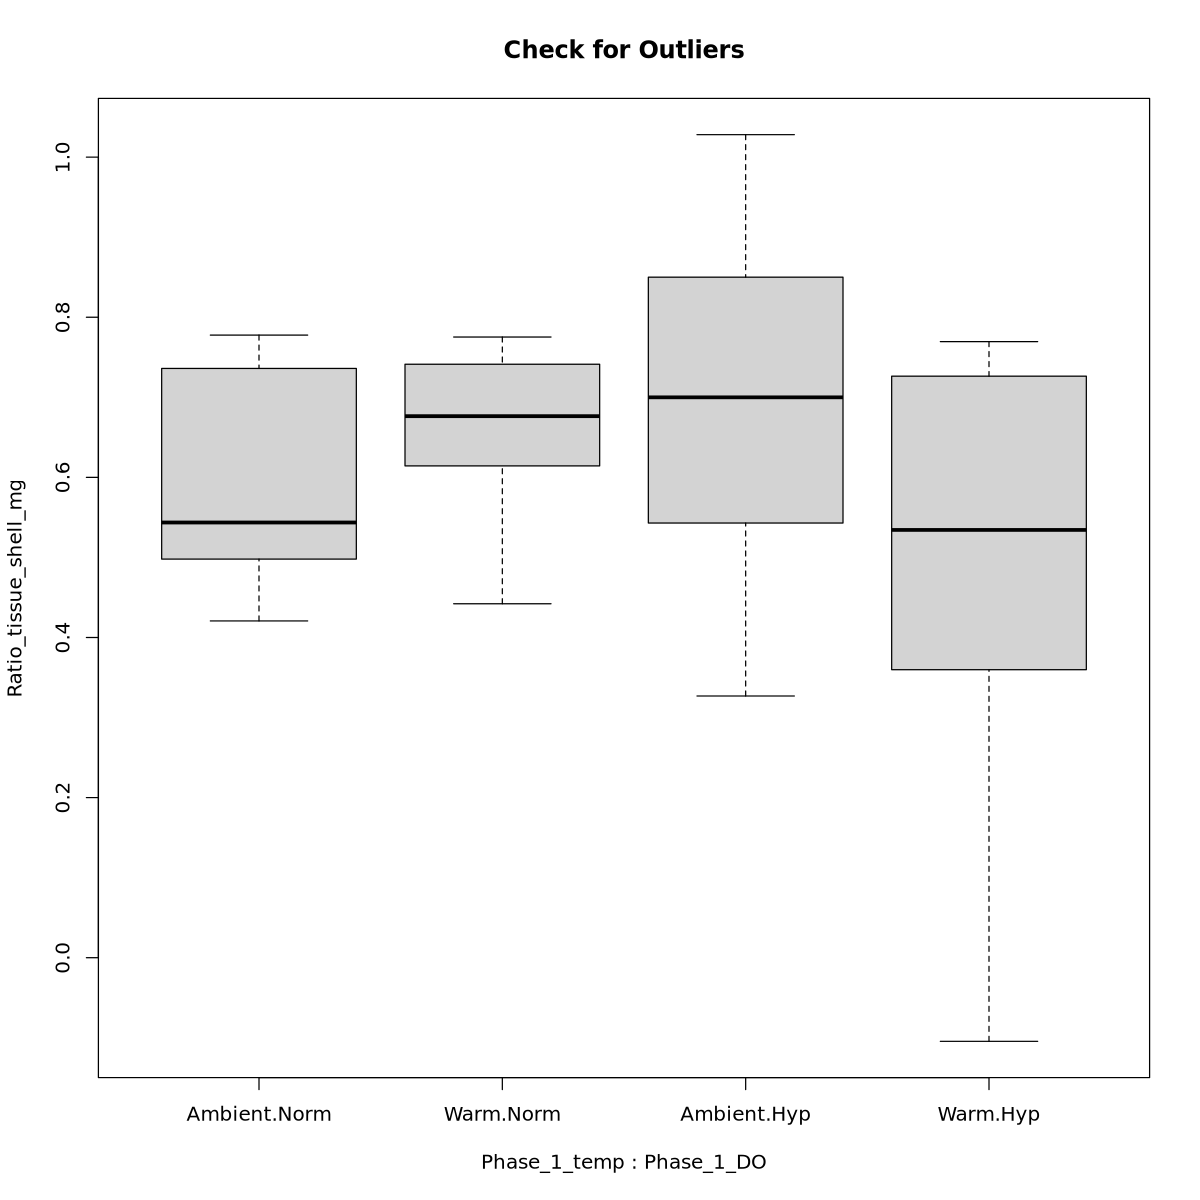

In [123]:
boxplot(Ratio_tissue_shell_mg ~ Phase_1_temp * Phase_1_DO, data = p1.ratio, main = "Check for Outliers")

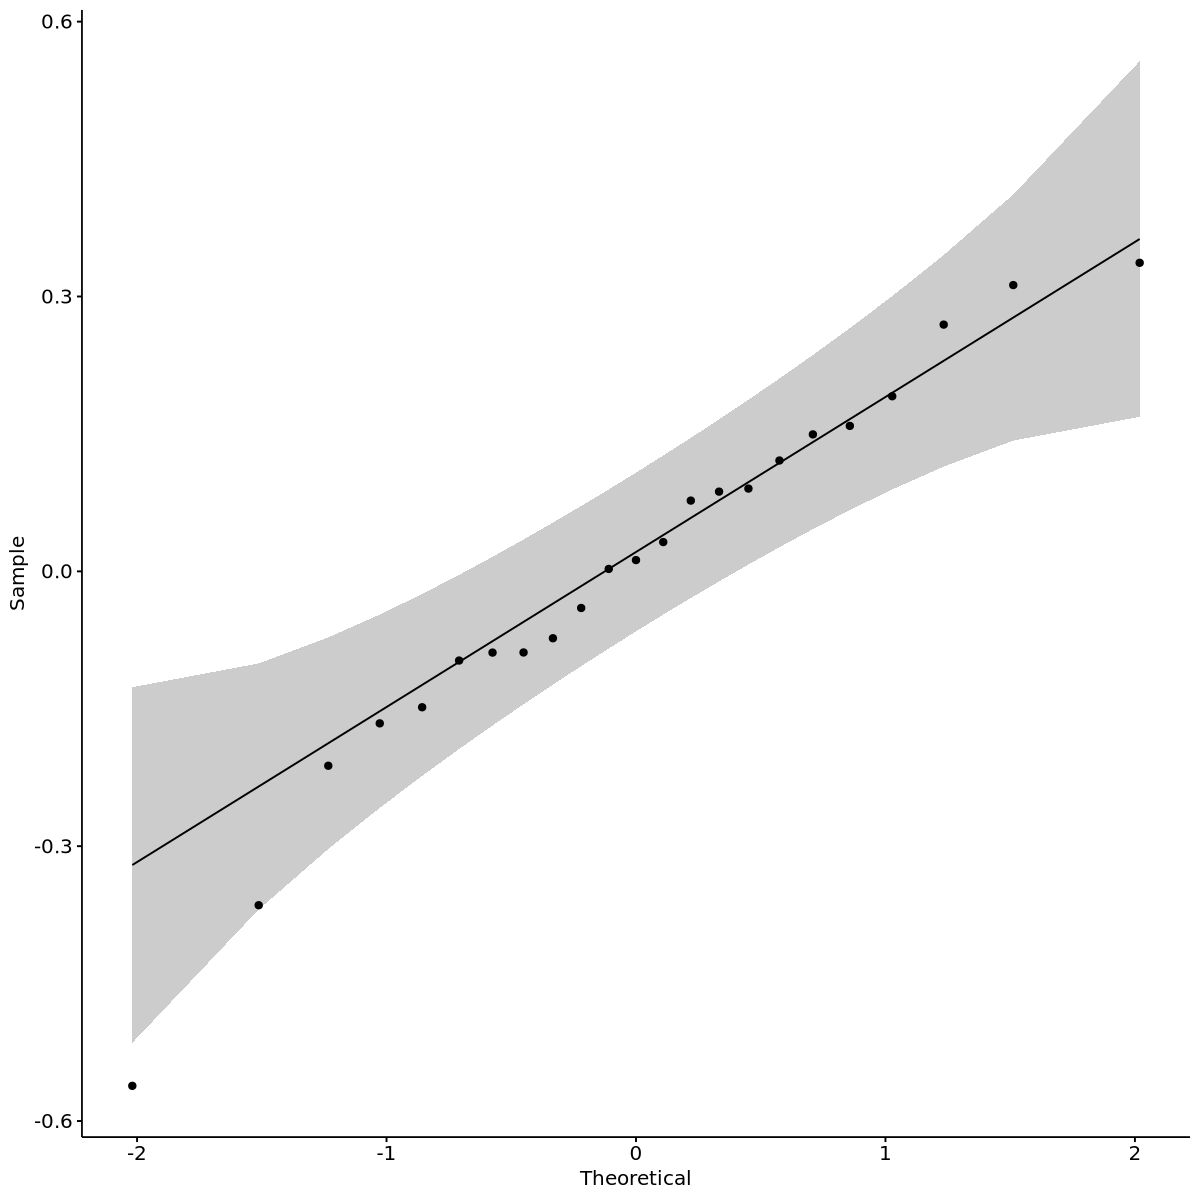

In [124]:
ggqqplot(residuals(ratio.anova))

points fall closely on this line

In [125]:
# normality
shapiro.test(residuals(ratio.anova))


	Shapiro-Wilk normality test

data:  residuals(ratio.anova)
W = 0.96051, p-value = 0.4737


null hypothesis (assumes normality) stands with non-significant pvalue

In [126]:
# homogeneity of variance
leveneTest(Ratio_tissue_shell_mg ~ Phase_1_temp * Phase_1_DO, data = p1.ratio)

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,3,1.653054,0.2107286
,19,NA,NA


confirms equal variances with non-significant pvalue